# Evidencia de los entrenamientos

Plantas medicinales. Recopilado el 14 de noviembre de 2026.

Este notebook reúne las corridas hechas hasta esa fecha. Las cifras salen de las salidas de los notebooks y de los JSON de métricas ya guardados. Las figuras están incrustadas en las celdas: al abrir el archivo se ven sin volver a entrenar y sin depender de las carpetas de resultados.

Notebooks de origen:

- `Modelo_deep_learning.ipynb`
- `entrenamiento_plantas_medicinales.ipynb`
- `comparacion_resnet50_mobilenetv2.ipynb`
- `entrenamiento_regional_colombia.ipynb`
- `entrenamiento_resnet50_regional.ipynb`
- `entrenamiento_mobilenetv2_estudiante_regional.ipynb` (el notebook no guardó salidas; la corrida sí quedó en `regional_colombia/resultados`)

No vuelvas a ejecutar las celdas de codigo: cada una solo imprime el resumen, y al correrla se sustituye la salida donde estan las figuras.


## Resumen

En flores el número es de validación, porque ese notebook no separó un test. En el resto es accuracy del conjunto de prueba. Top-3 y duración aparecen solo cuando el archivo de métricas los guardó.

| Entrenamiento | Dataset | Conjunto | Accuracy | Top-3 | Errores | Duración | Dónde está |
| --- | --- | --- | --- | --- | --- | --- | --- |
| CNN flores, red 1 | Flores, 5 clases | validación | 61,3 % | — | 734 val | — | `Modelo_deep_learning.ipynb` |
| CNN flores, red 2 con dropout | Flores, 5 clases | validación | 60,5 % | — | 734 val | — | `Modelo_deep_learning.ipynb` |
| MobileNetV2, intento 1 | Herbify, 57 especies | test | 91,2 % | — | 67 / 761 | — | `entrenamiento_plantas_medicinales.ipynb` |
| MobileNetV2, intento 2 (CPU) | Herbify, 57 especies | test | 88,0 % | 96,7 % | 91 / 761 | 16,9 min | `modelos_livianos` |
| MobileNetV3Small | Herbify, 57 especies | test | 81,6 % | 93,4 % | 140 / 761 | 5,3 min | `modelos_livianos` |
| ResNet50 | Herbify, 57 especies | test | 93,0 % | 98,7 % | 53 / 761 | 40,8 min | `comparacion_resnet50_mobilenetv2.ipynb` |
| EfficientNetB0 | Herbify, 57 especies | test | 89,4 % | 97,9 % | 81 / 761 | 37,5 min | `comparacion_resnet50_mobilenetv2.ipynb` |
| MobileNetV2, comparación | Herbify, 57 especies | test | 88,8 % | 96,7 % | 85 / 761 | 42,8 min | `comparacion_resnet50_mobilenetv2.ipynb` |
| MobileNetV3Small alumno de ResNet50 | Herbify, 57 especies | test | 76,5 % | 90,7 % | 179 / 761 | 300,8 min | `comparacion_resnet50_mobilenetv2.ipynb` |
| MobileNetV2 regional, 10 especies | Colombia / Tolima | test | 73,8 % | — | 79 / 301 | — | `resultados, archivado` |
| MobileNetV2 regional, 20 especies | Colombia / Tolima | test | 77,4 % | — | 304 / 1347 | — | `entrenamiento_regional_colombia.ipynb` |
| MobileNetV2 regional, 20 especies, L1/L2 | Colombia / Tolima | test | 71,9 % | 88,9 % | 378 / 1347 | 81,1 min | `entrenar_regional.py` |
| MobileNetV2 regional, 29 especies | Colombia / Tolima + huerta | test | 68,0 % | 85,4 % | 705 / 2201 | 157,3 min | `metricas_regional_29.json` |
| ResNet50 regional, 29 especies | Colombia / Tolima + huerta | test | 76,5 % | 89,2 % | 517 / 2201 | 164,3 min | `entrenamiento_resnet50_regional.ipynb` |
| MobileNetV2 estudiante del ResNet50 regional | Colombia / Tolima + huerta | test | 69,5 % | 84,4 % | 671 / 2201 | 186,2 min | `entrenar_estudiante_v2.py` |


## 1. Ensayo con flores

Corrida de práctica en `Modelo_deep_learning.ipynb`, antes del dataset de plantas medicinales. Son 3.670 fotos de cinco flores (daisy, dandelion, roses, sunflowers, tulips), repartidas en 2.936 de entrenamiento y 734 de validación.

La primera red es una CNN de dos convoluciones y una capa densa de 128 unidades (15.167.173 parámetros), Adam, 10 épocas, imágenes de 180×180. Accuracy de validación: **61,3 %**.

La segunda agrega dropout. La época 10/10 cierra en **60,5 %** de accuracy de validación.


CNN flores · validación 61,3 % (red 1) y 60,5 % (red 2, época 10)


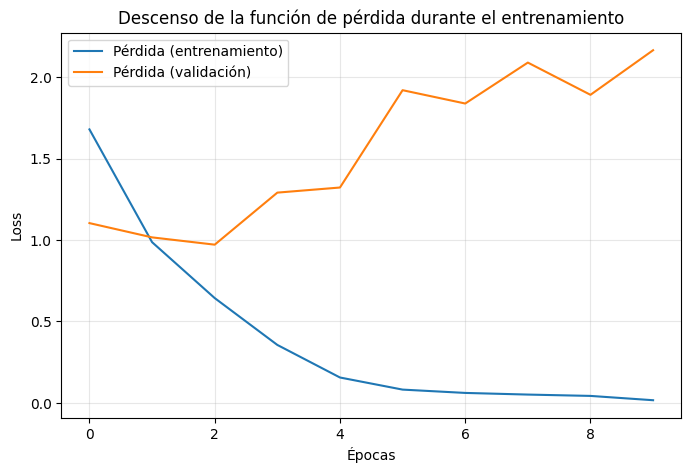

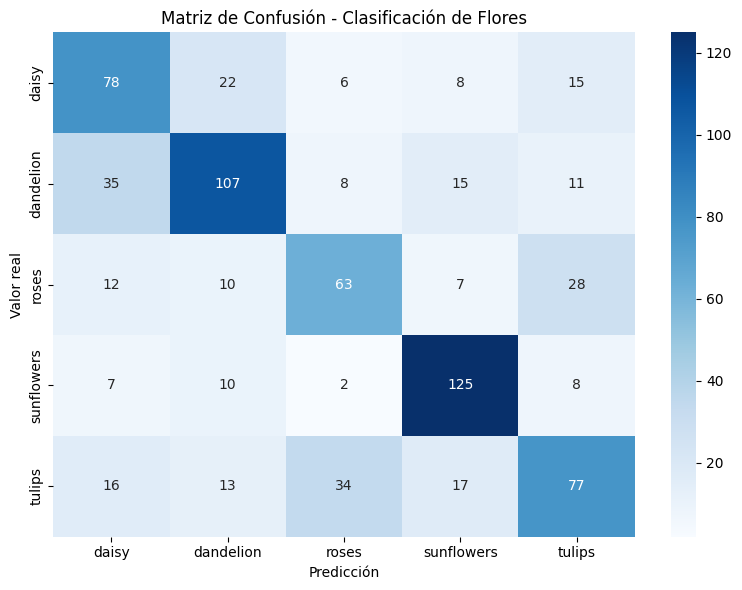

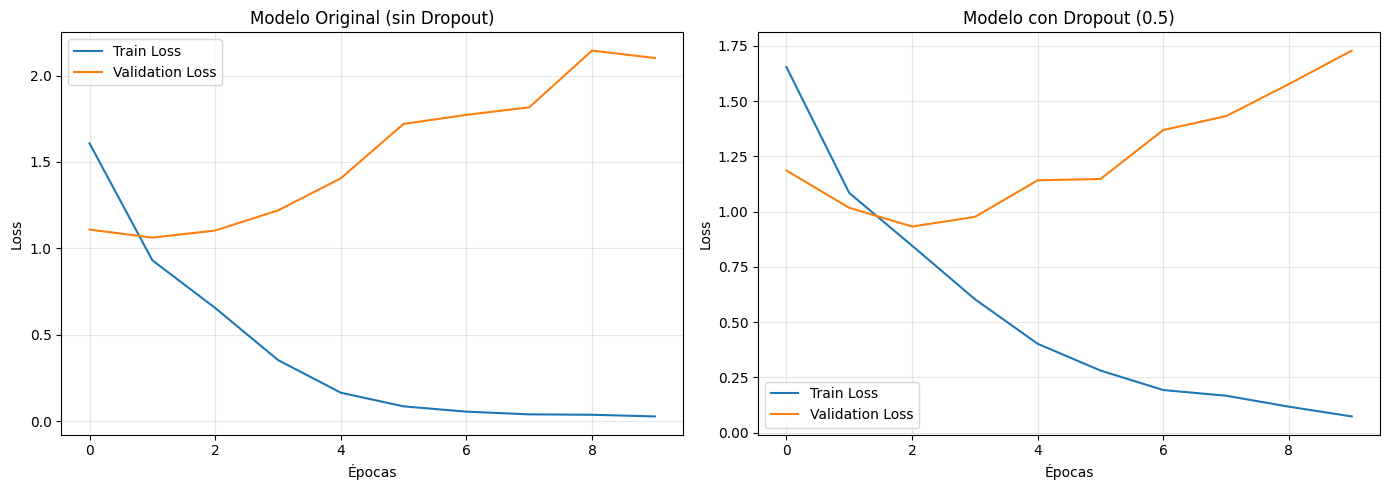

In [1]:
# Salidas incrustadas de Modelo_deep_learning.ipynb
print('CNN flores · validación 61,3 % (red 1) y 60,5 % (red 2, época 10)')


## 2. Herbify, MobileNetV2, intento 1

Notebook `entrenamiento_plantas_medicinales.ipynb`. Dataset Herbify de Kaggle, 57 especies con al menos 50 fotos (4.903 imágenes útiles). Split 70/15/15: 3.408 train, 734 validación, 761 test.

MobileNetV2 con pesos de ImageNet, imagen 224, lote 16, dropout y augmentación solo en entrenamiento. Fase 1: base congelada, 25/25 épocas; la última queda en 86,9 % de accuracy de validación. Fase 2: últimas 40 capas descongeladas; la parada temprana corta en la época 13/20. El mejor accuracy de validación de esa fase es 90,3 % (época 7).

Con los mejores pesos restaurados, el test da **91,2 %** (67 errores de 761). F1 ponderado 91,4 %. El modelo quedó en `modelo_plantas.h5`.


MobileNetV2 intento 1 · Herbify · test 91,2 % · 67 errores de 761


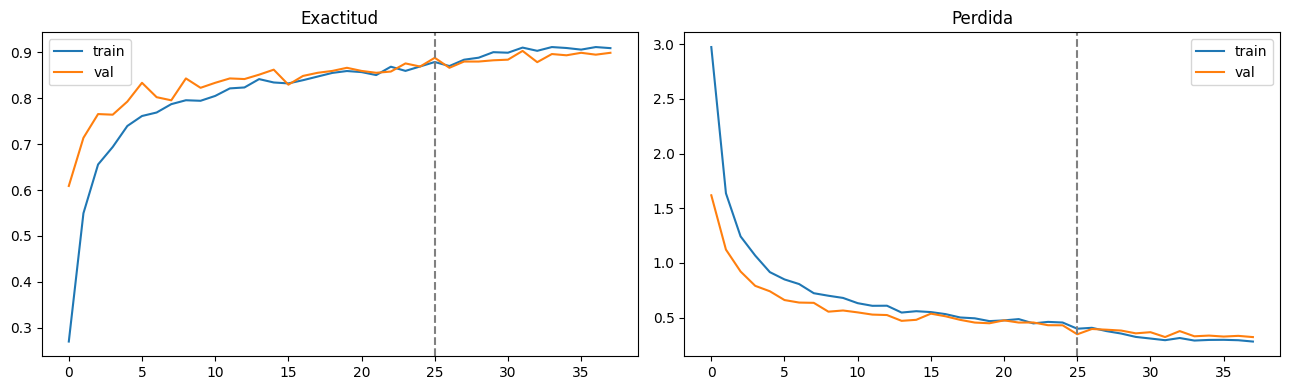

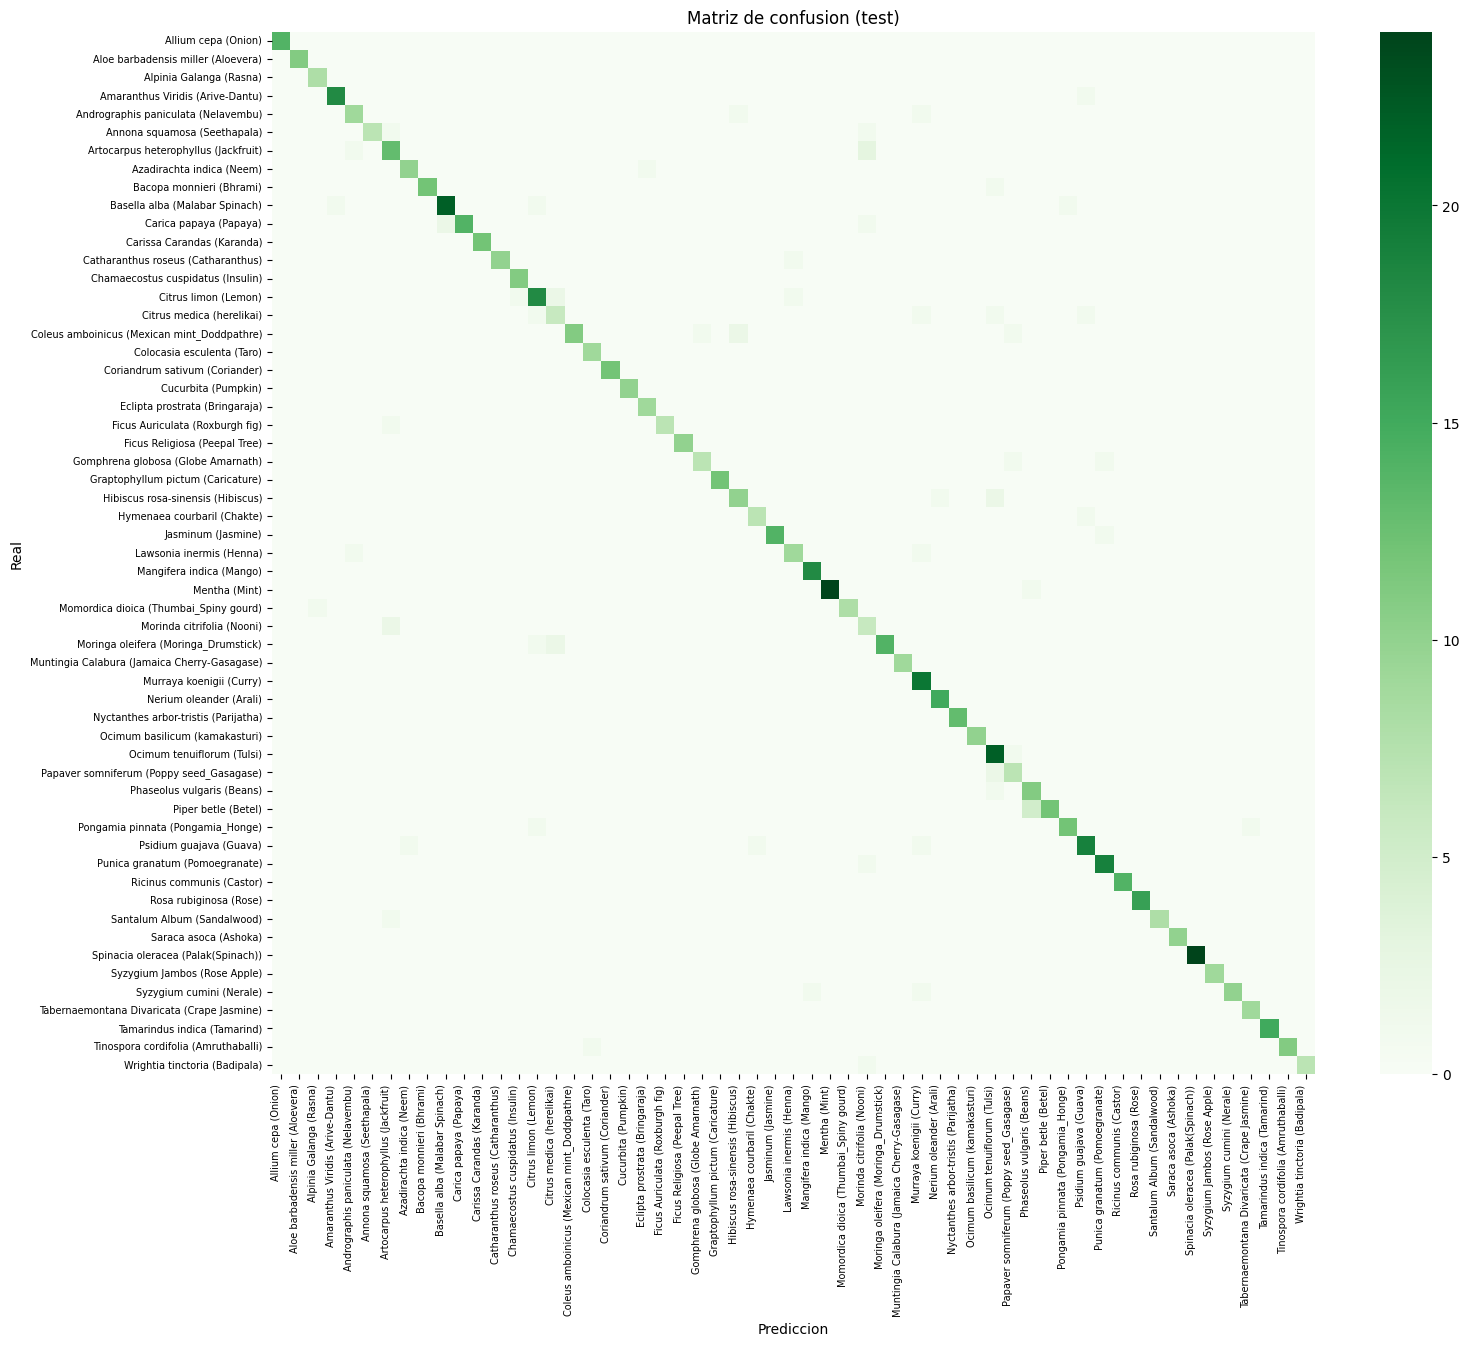

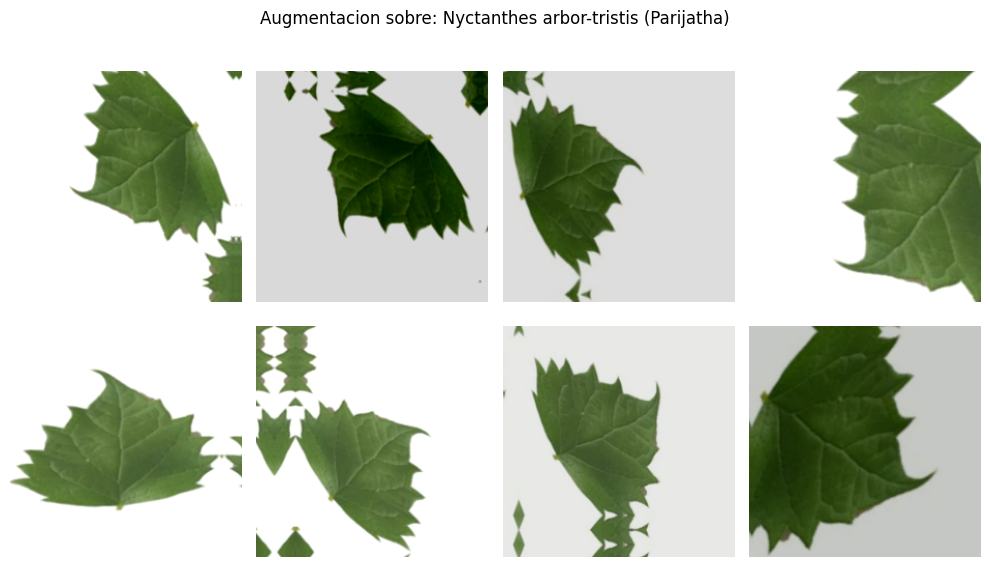

In [1]:
# Figuras del intento 1, guardadas para el informe
print('MobileNetV2 intento 1 · Herbify · test 91,2 % · 67 errores de 761')


## 3. Herbify en CPU: MobileNetV2 y MobileNetV3Small

Misma partición Herbify (semilla 42, 3.408 / 734 / 761). Estas dos corridas salen del script ligero y dejan métricas en `modelos_livianos/`.

MobileNetV2: fase 1 corrió 14 de 20 épocas y fase 2 las 15 pedidas. Test **88,0 %**, top-3 96,7 %, 91 errores, 16,9 min, 2.331.001 parámetros, mejor validación 88,0 %.

MobileNetV3Small: fase 1 completa (20 épocas) y fase 2 cortada en la época 6 de 15. Test **81,6 %**, top-3 93,4 %, 140 errores, 5,3 min, 972.009 parámetros.


CPU · MobileNetV2 test 88,0 % · MobileNetV3Small test 81,6 %


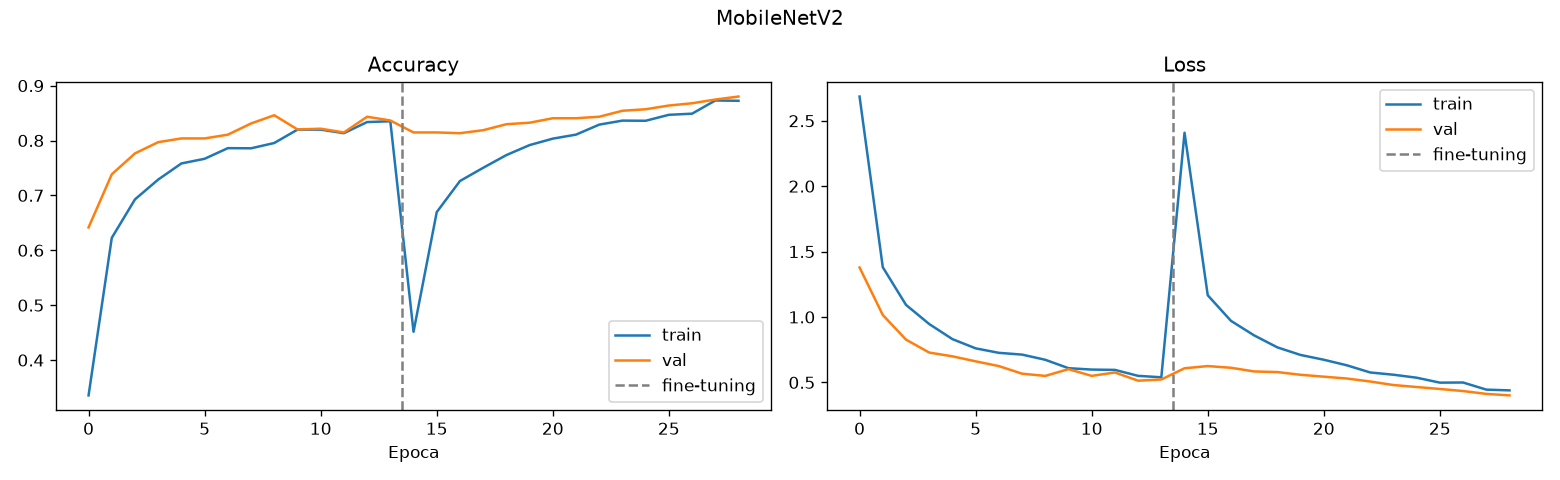

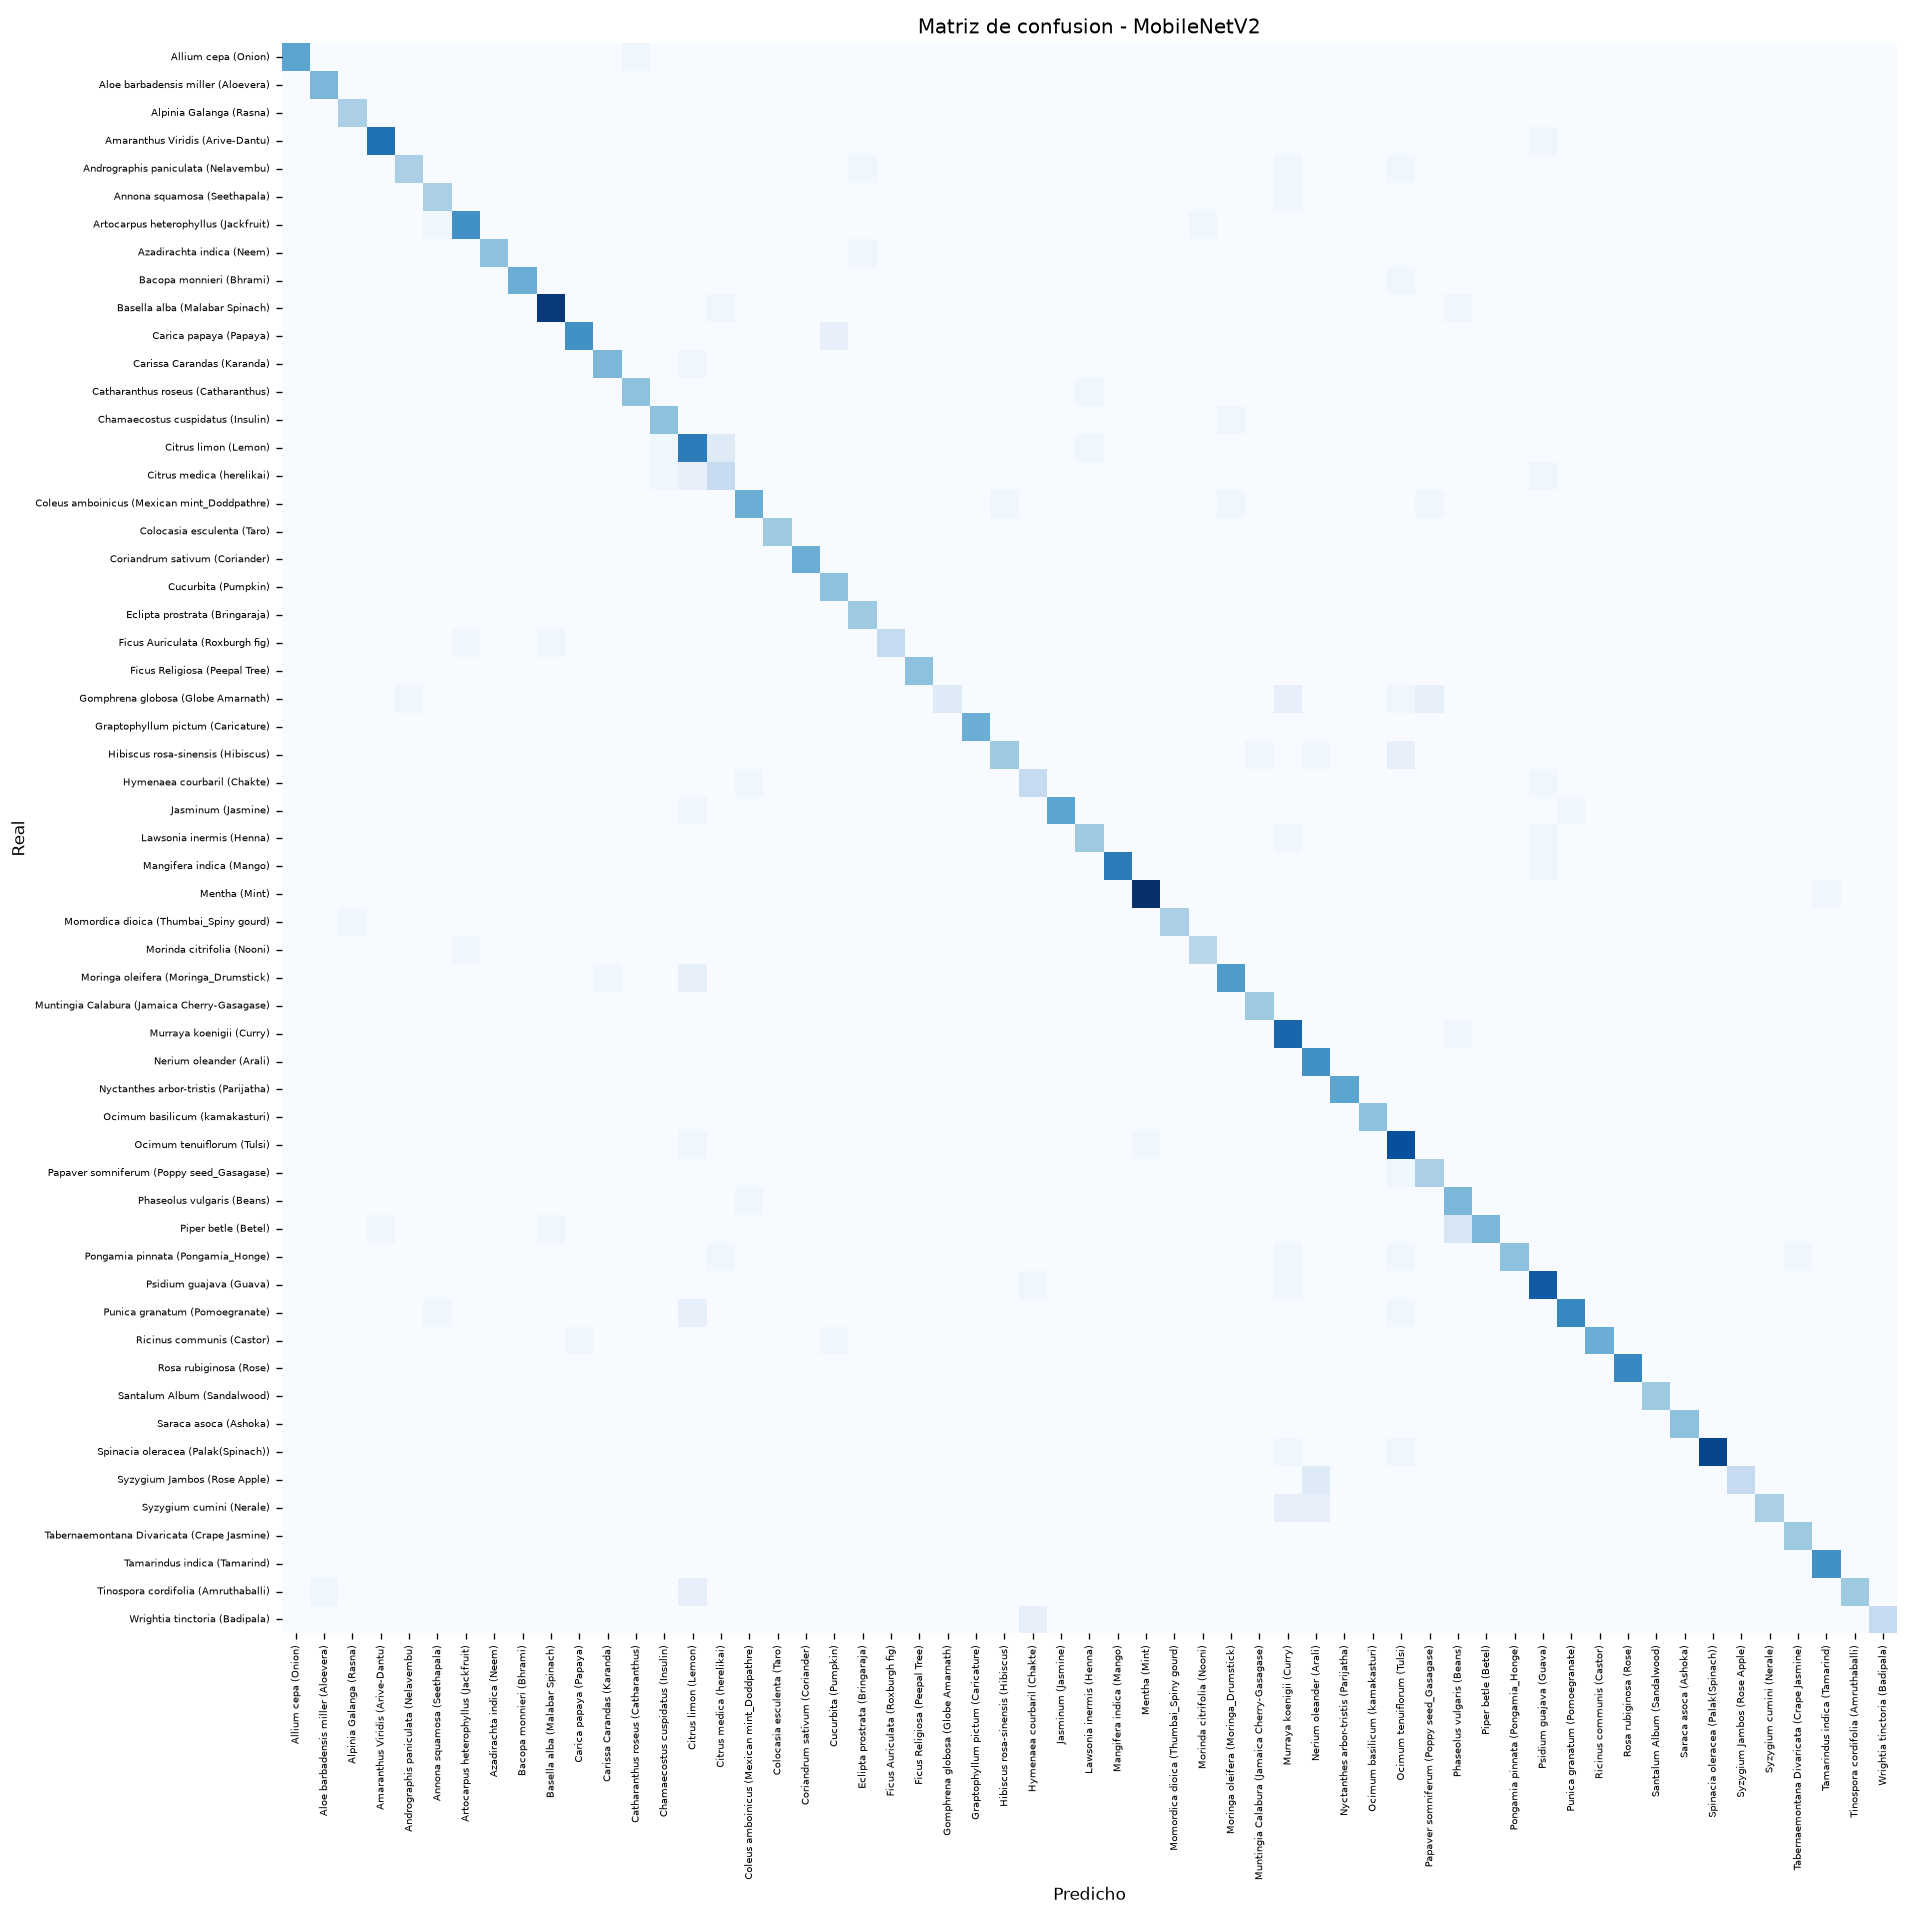

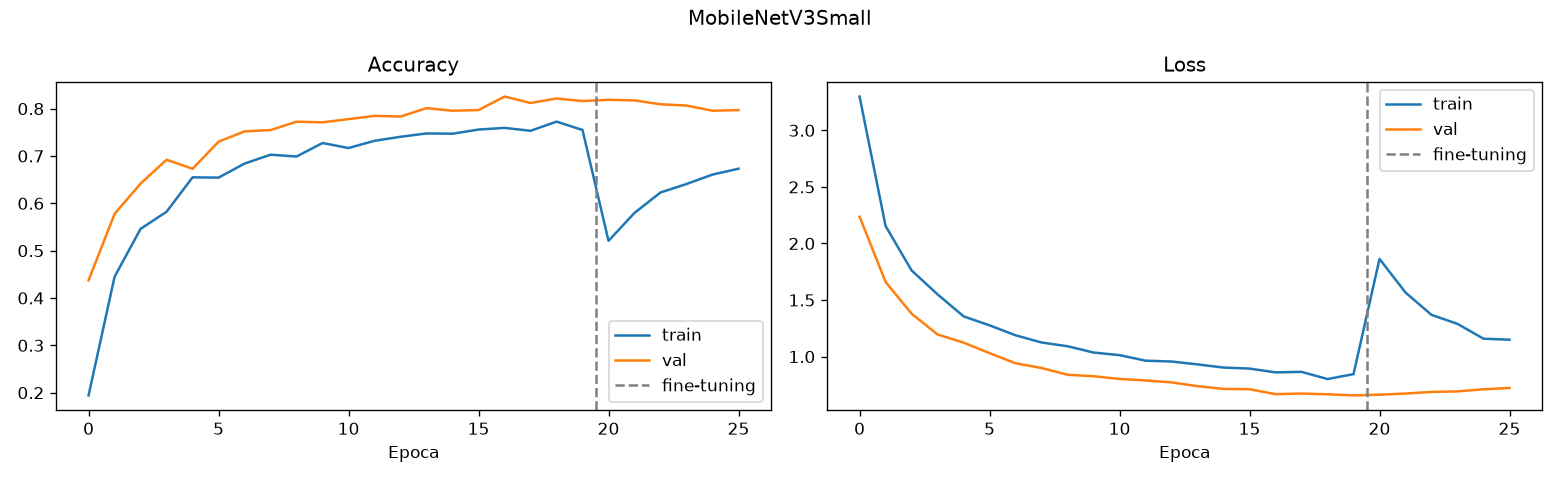

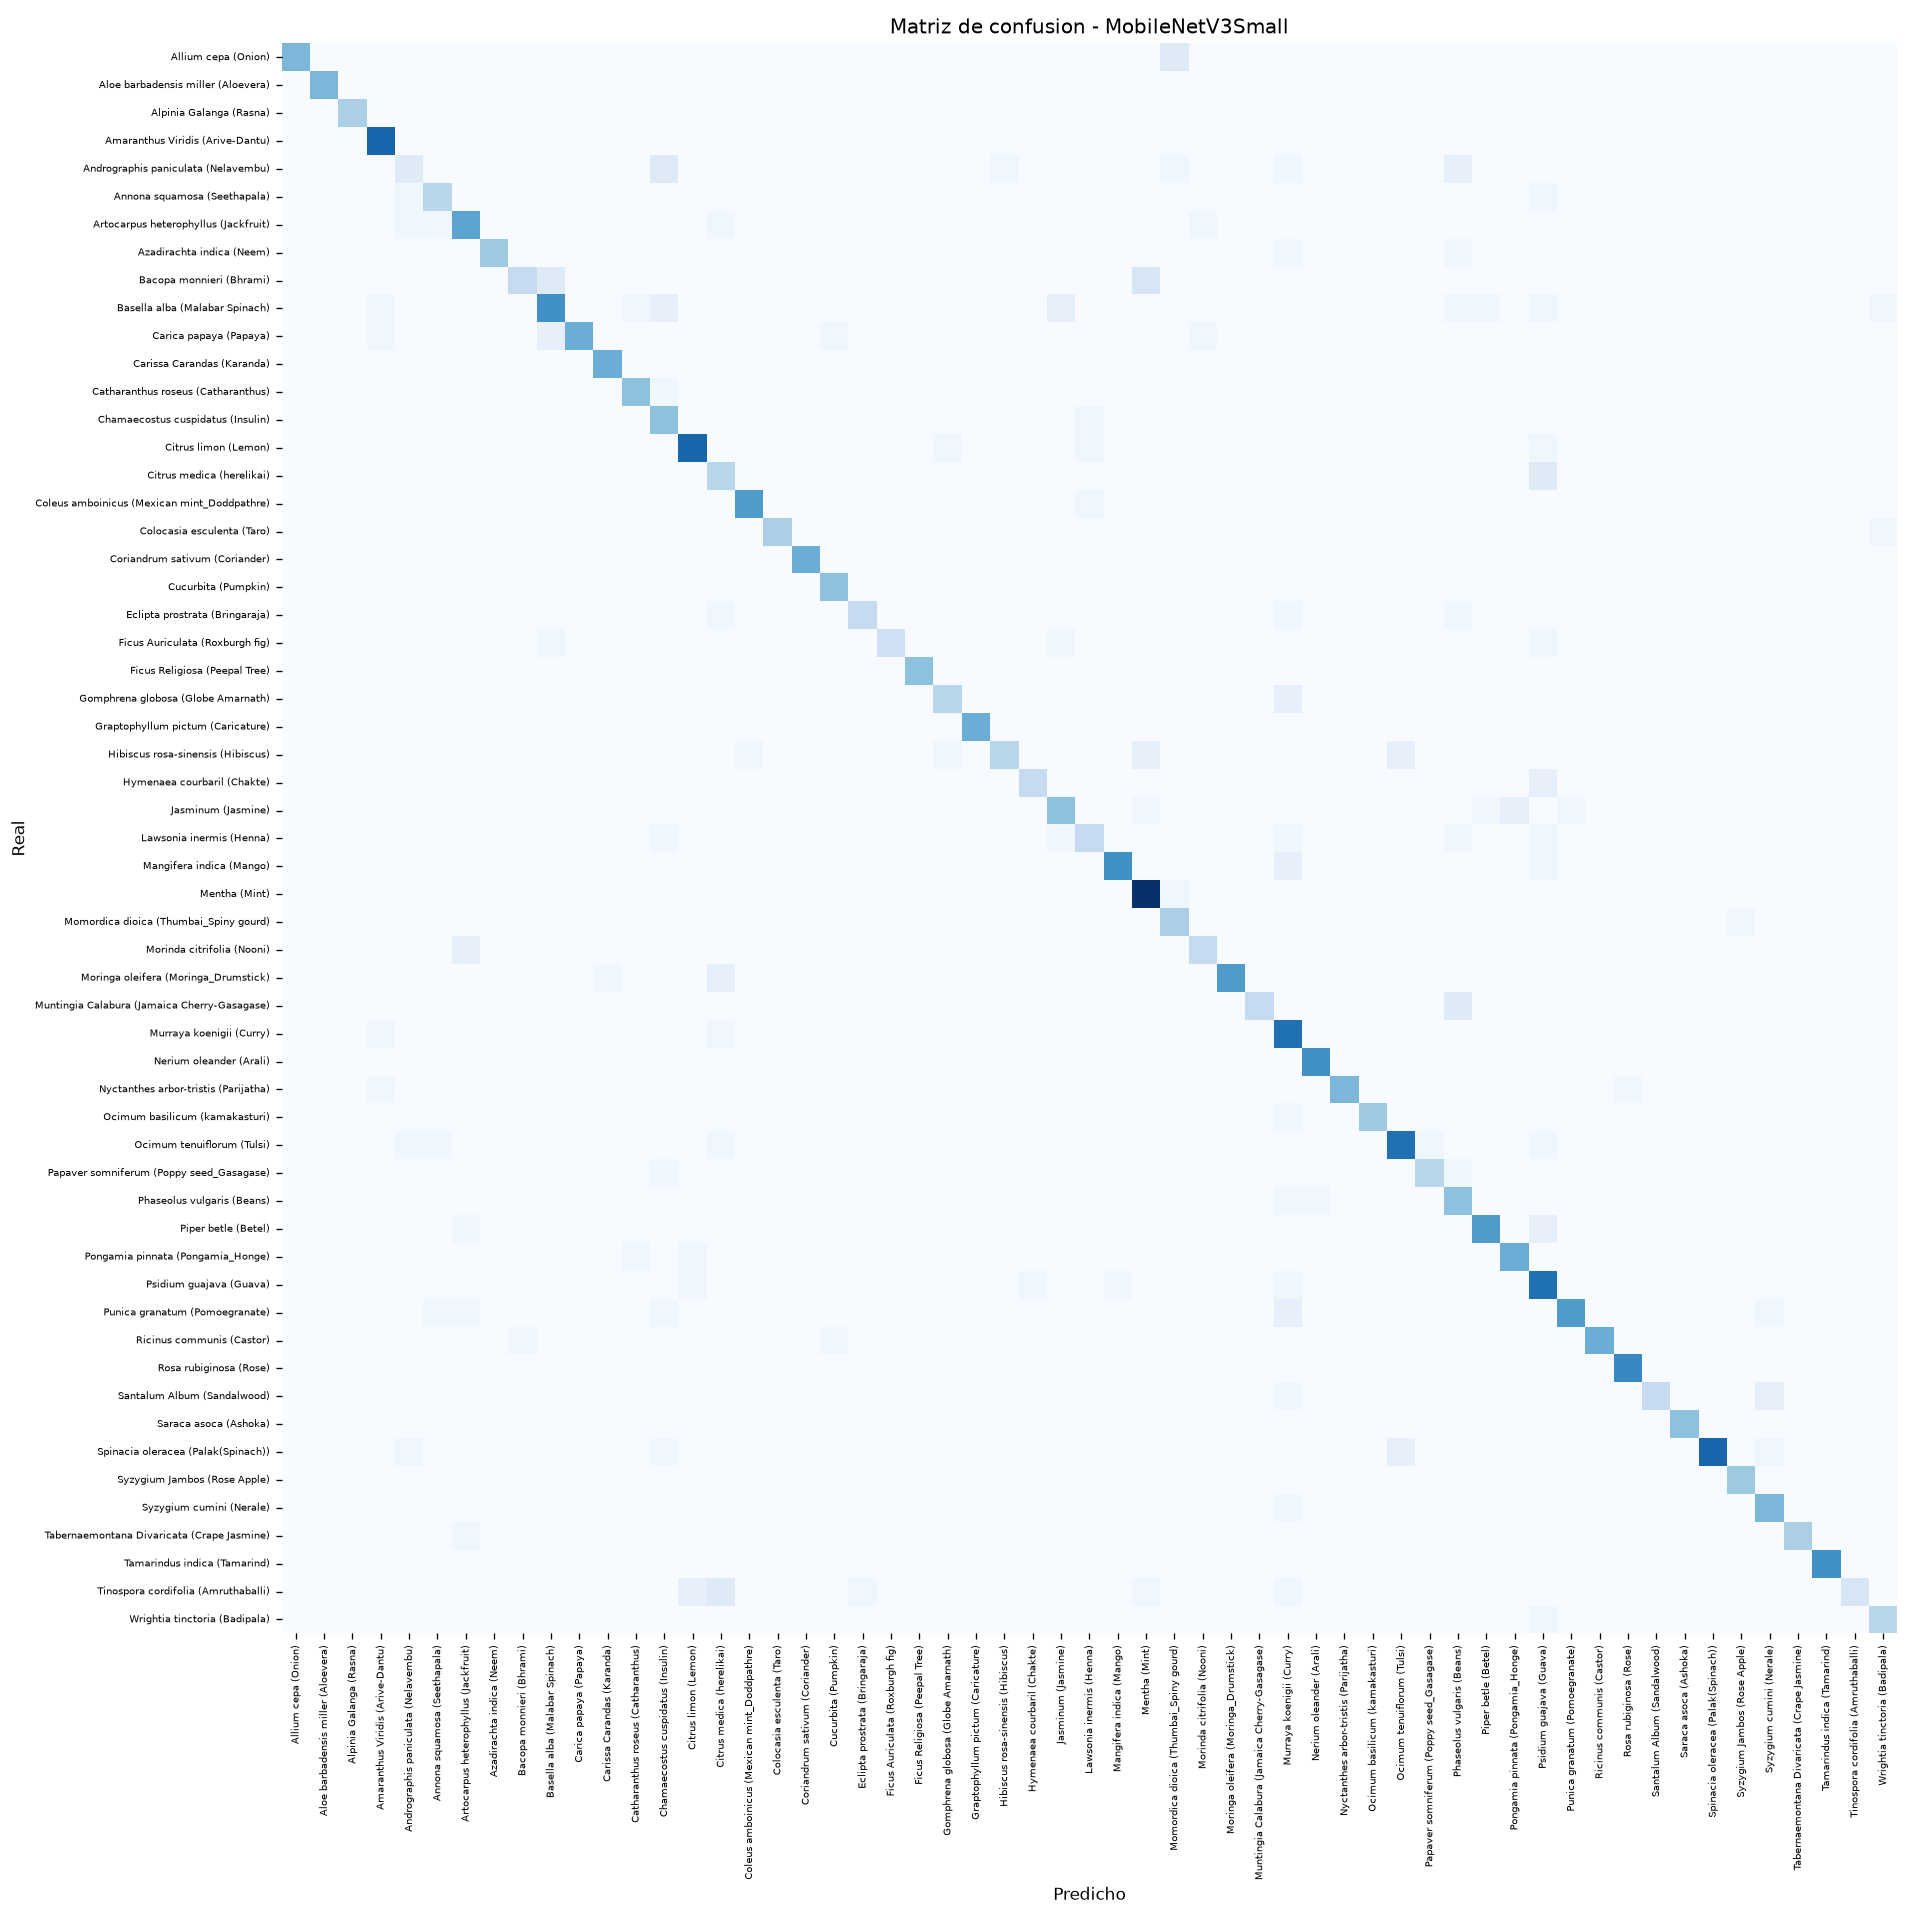

In [1]:
# modelos_livianos/curvas y matrices
print('CPU · MobileNetV2 test 88,0 % · MobileNetV3Small test 81,6 %')


## 4. Comparación en GPU: ResNet50, EfficientNetB0 y MobileNetV2

Notebook `comparacion_resnet50_mobilenetv2.ipynb`, TensorFlow 2.10.1 con GPU. Las tres redes usan el mismo split Herbify, la misma augmentación y el mismo protocolo de dos fases. Evaluación sobre las 761 imágenes de test, repetida en `resultados_comparacion/`.

- ResNet50: **93,0 %**, top-3 98,7 %, 53 errores, 40,8 min, 23.704.505 parámetros, archivo de 212.53 MB.
- EfficientNetB0: **89,4 %**, top-3 97,9 %, 81 errores, 37,5 min, 4.122.588 parámetros.
- MobileNetV2: **88,8 %**, top-3 96,7 %, 85 errores, 42,8 min, 2.331.001 parámetros.


Herbify GPU · ResNet50 93,0 % · EfficientNetB0 89,4 % · MobileNetV2 88,8 %


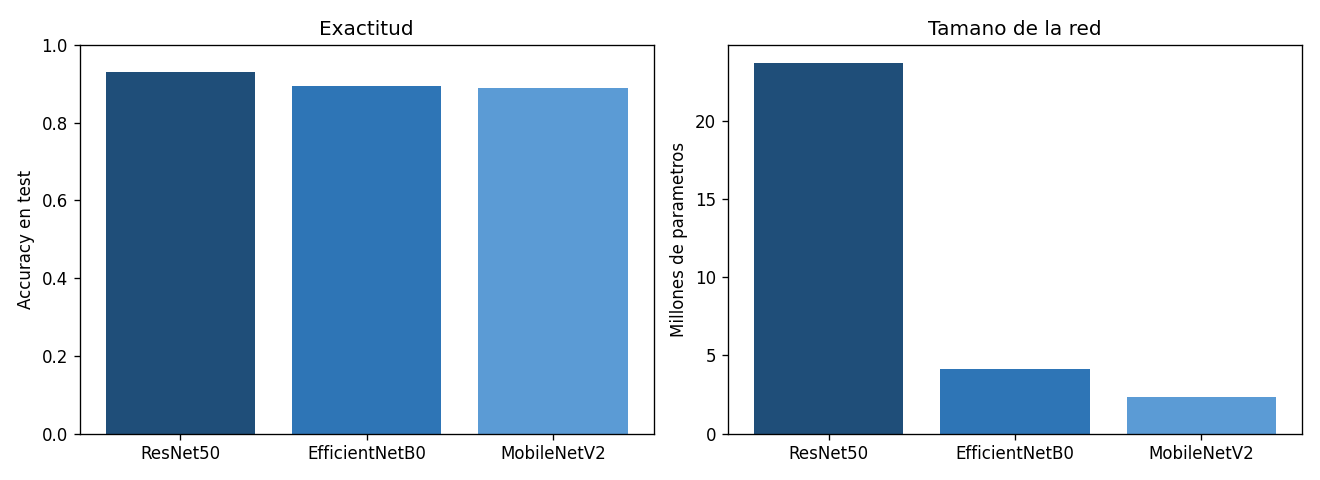

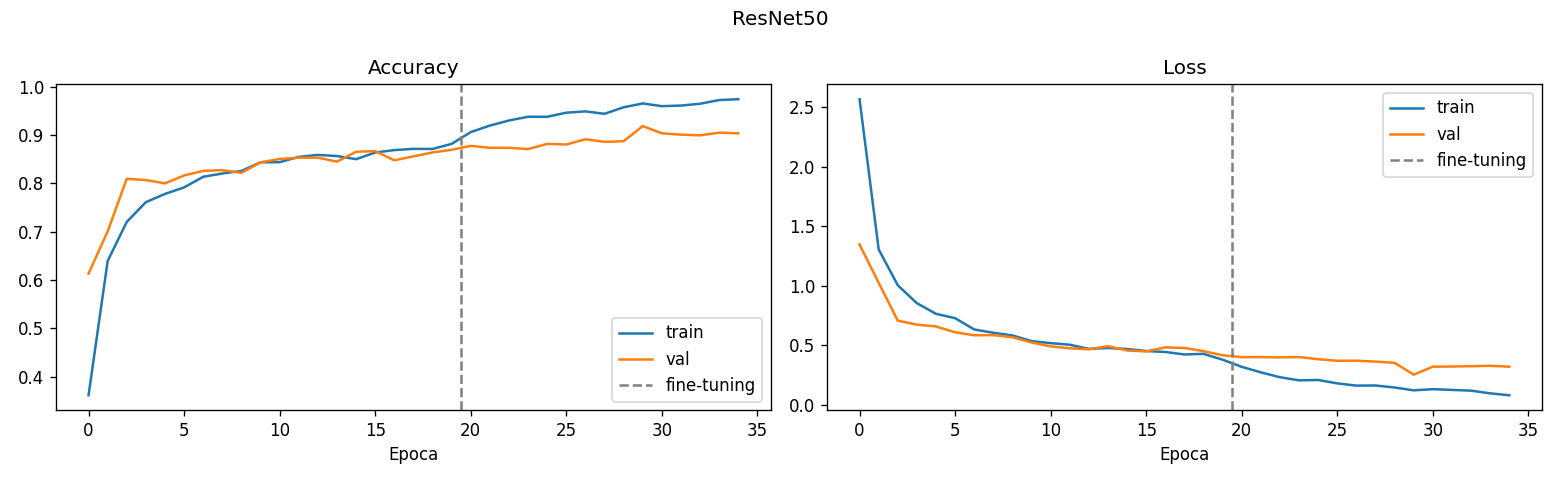

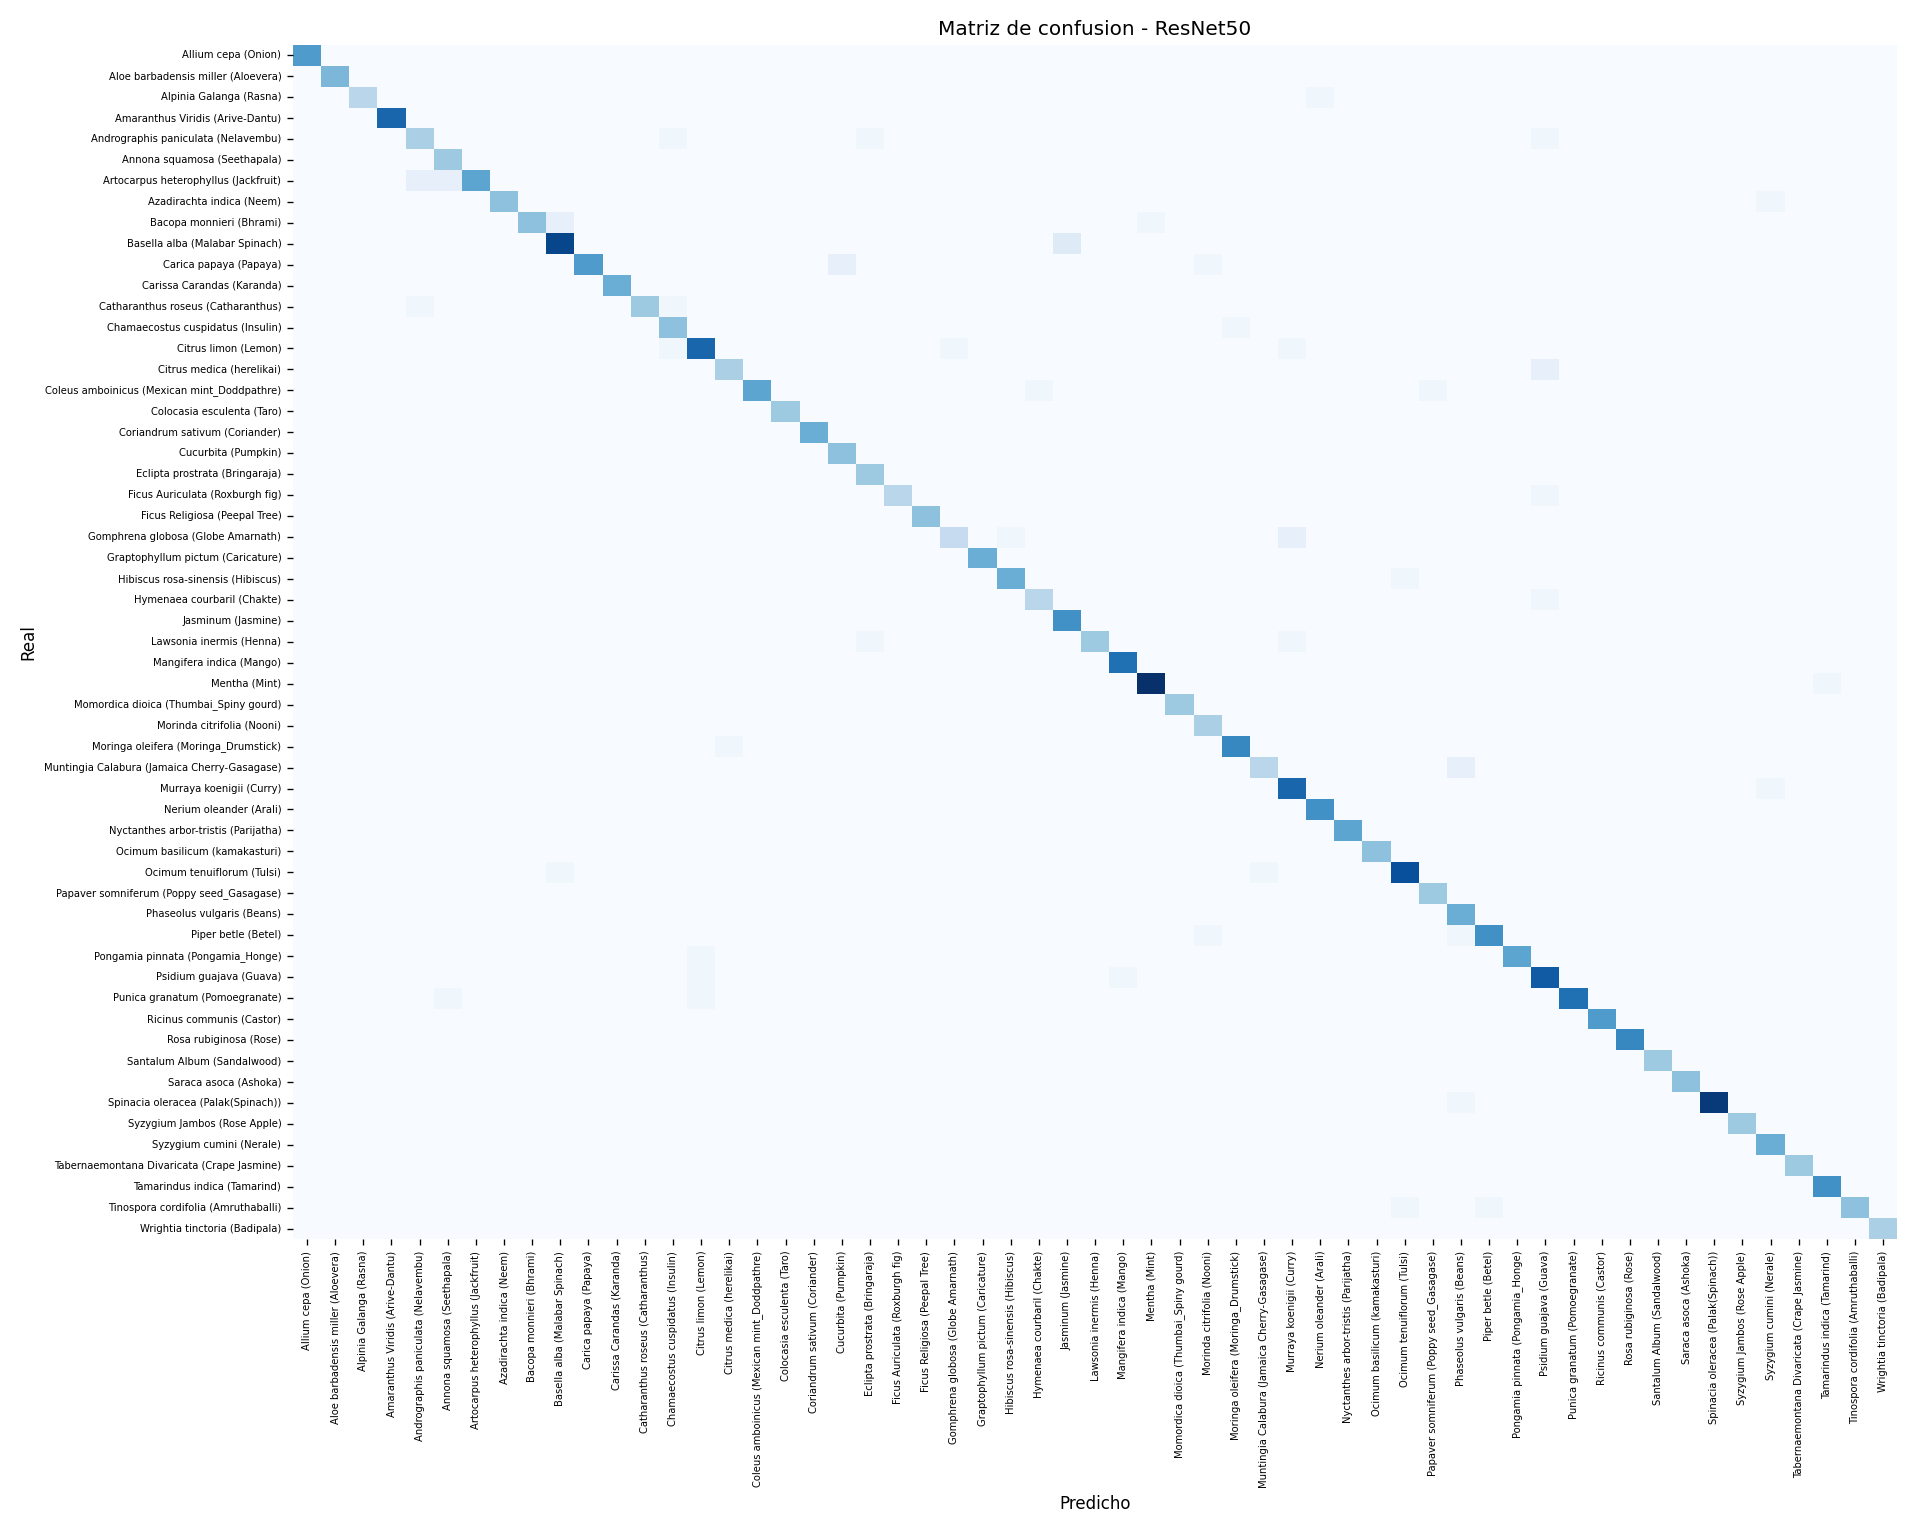

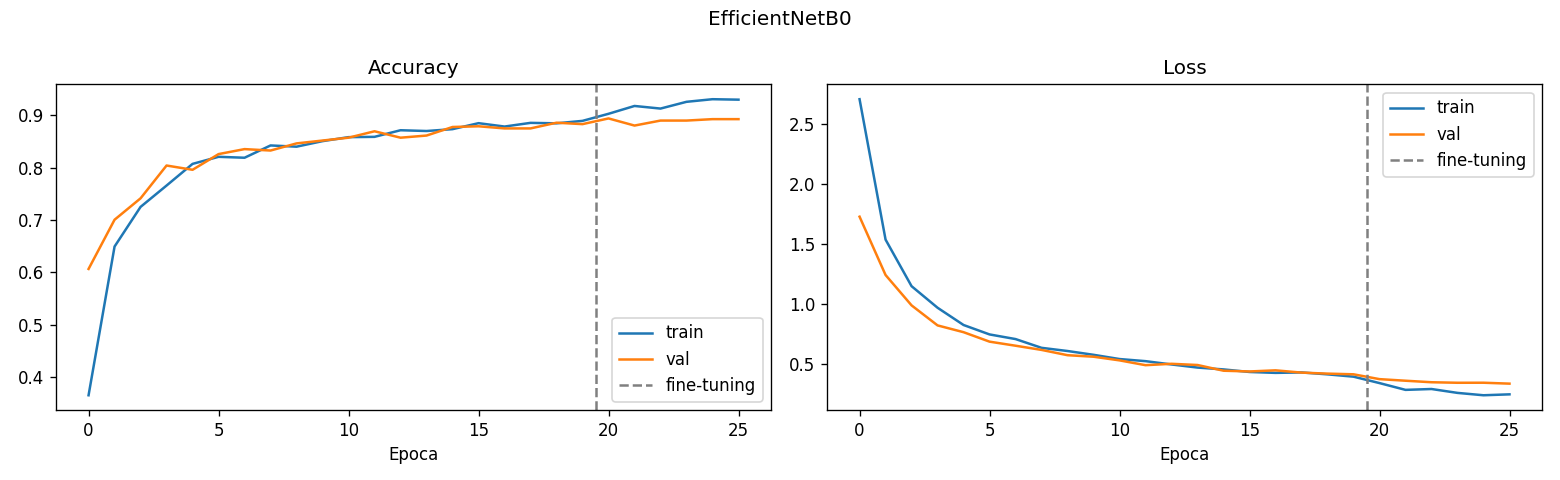

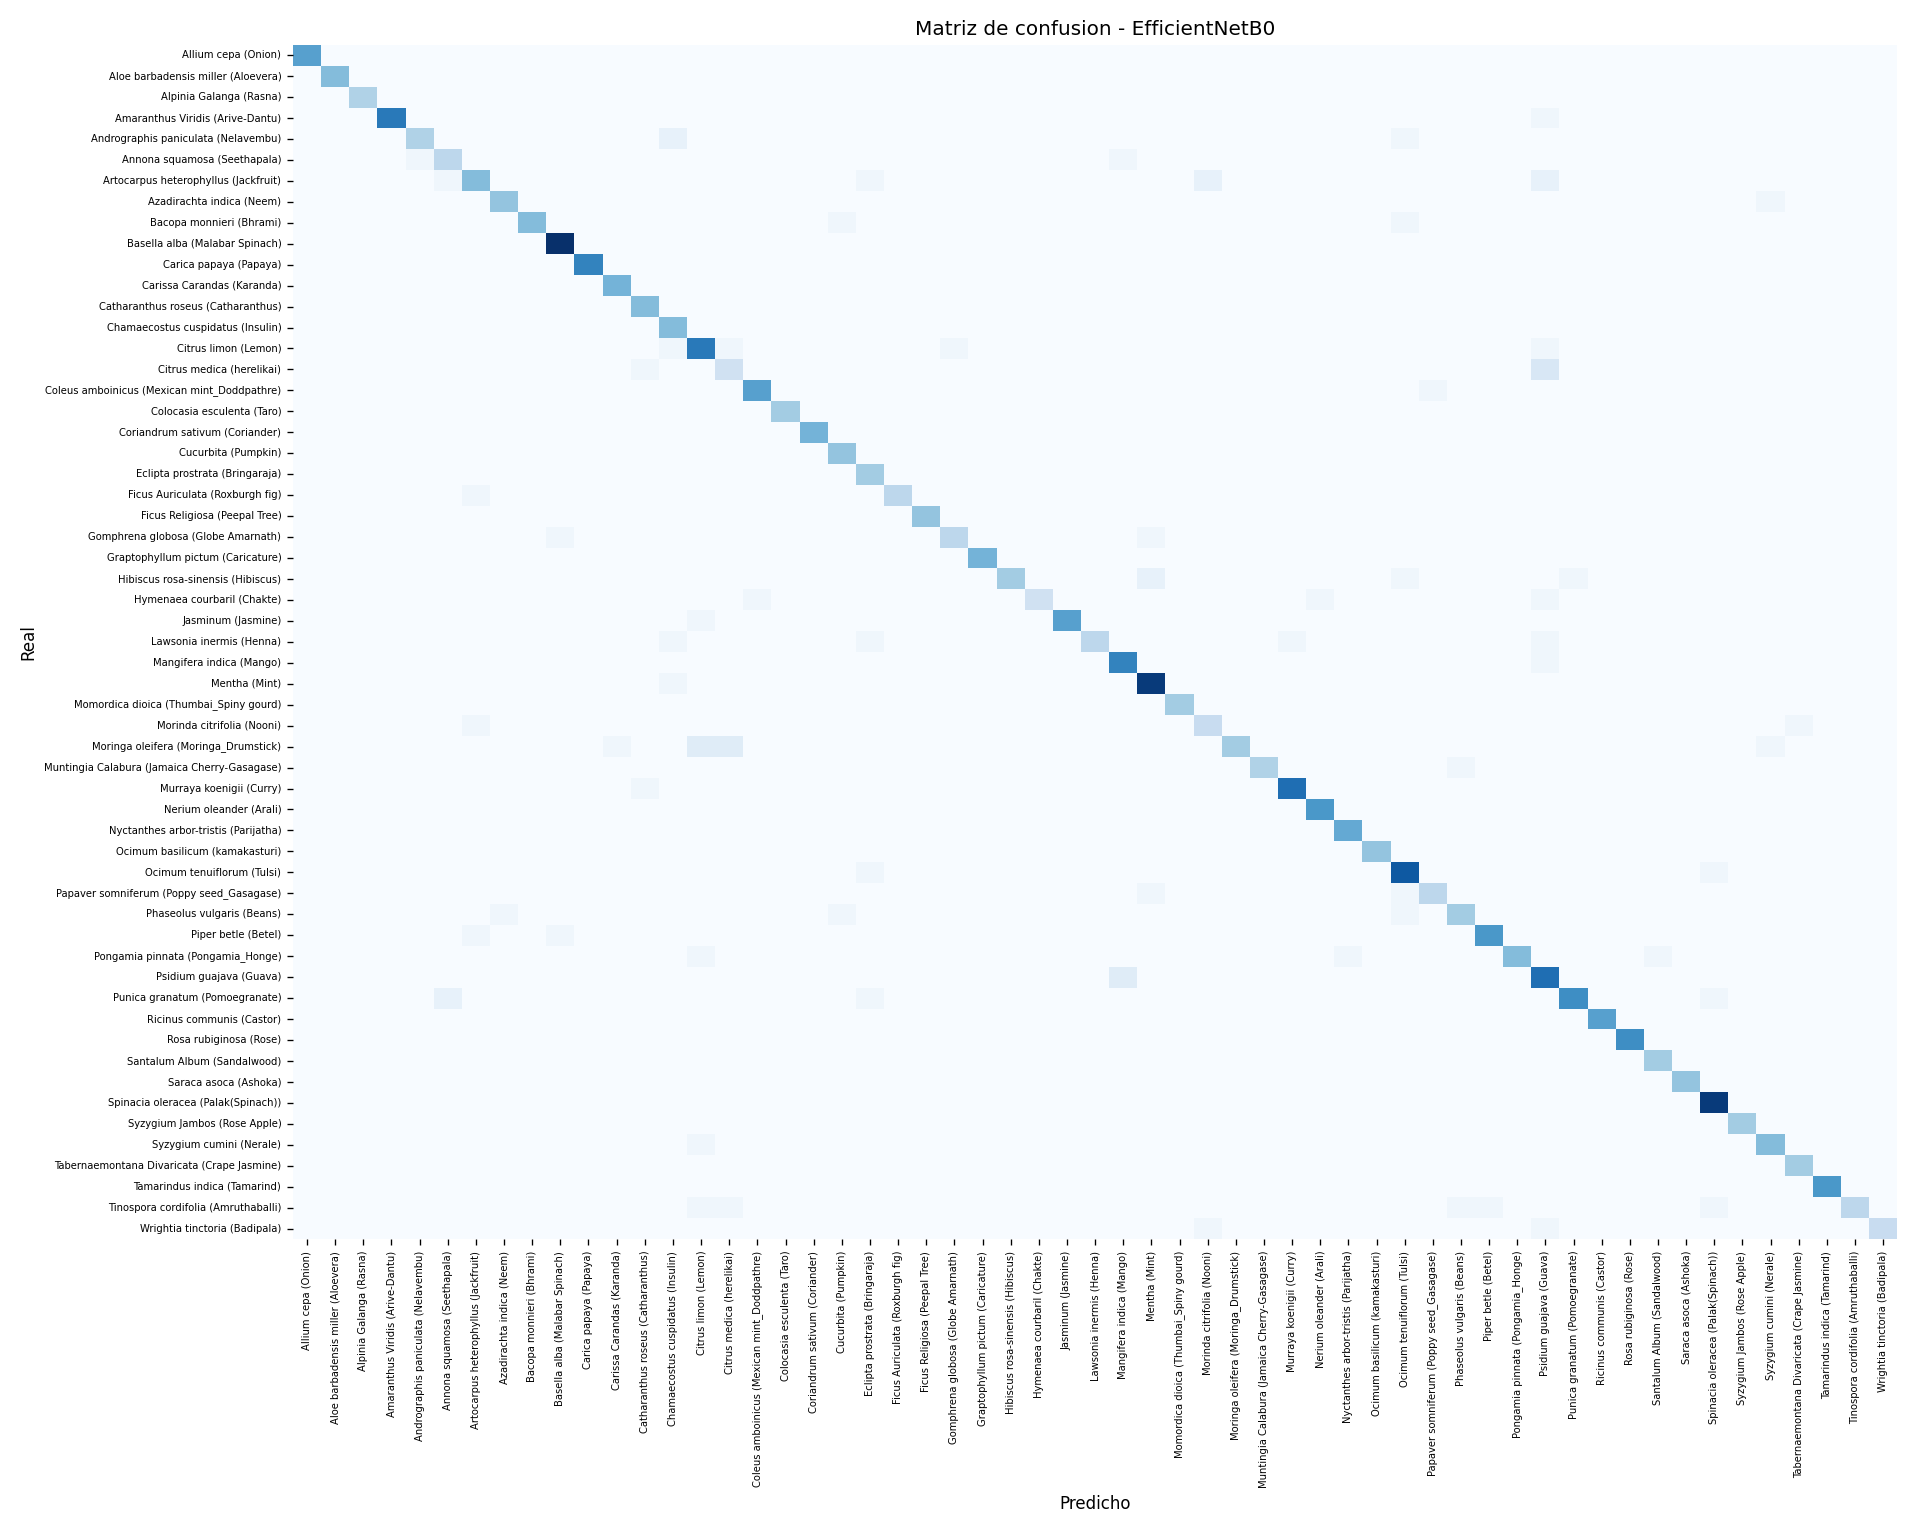

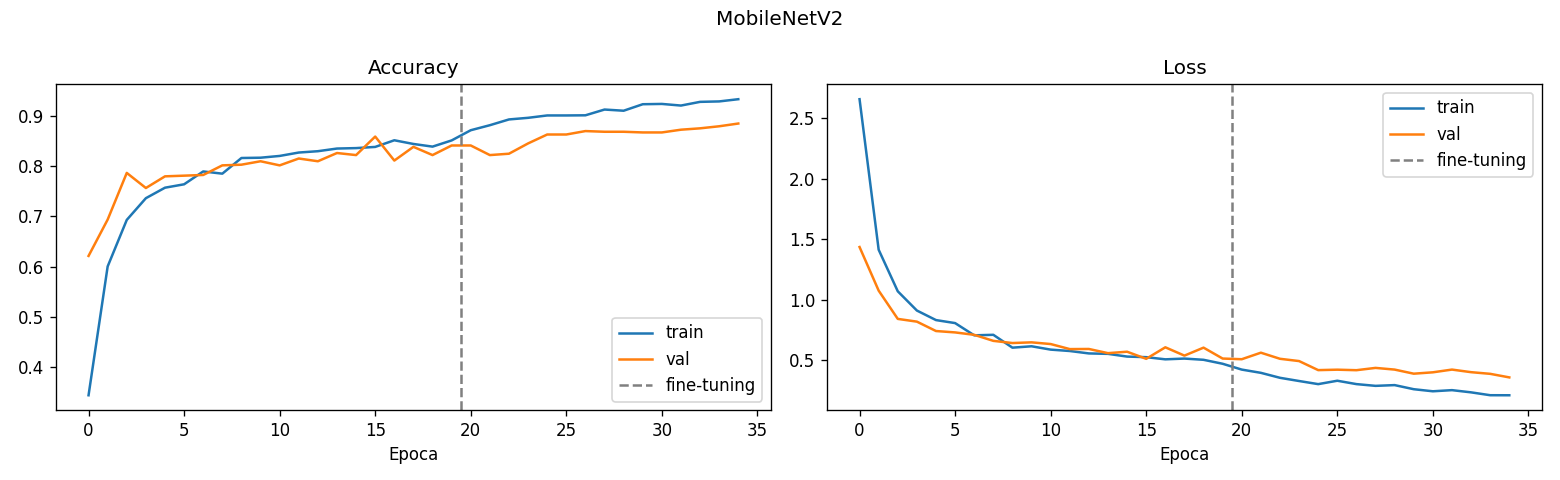

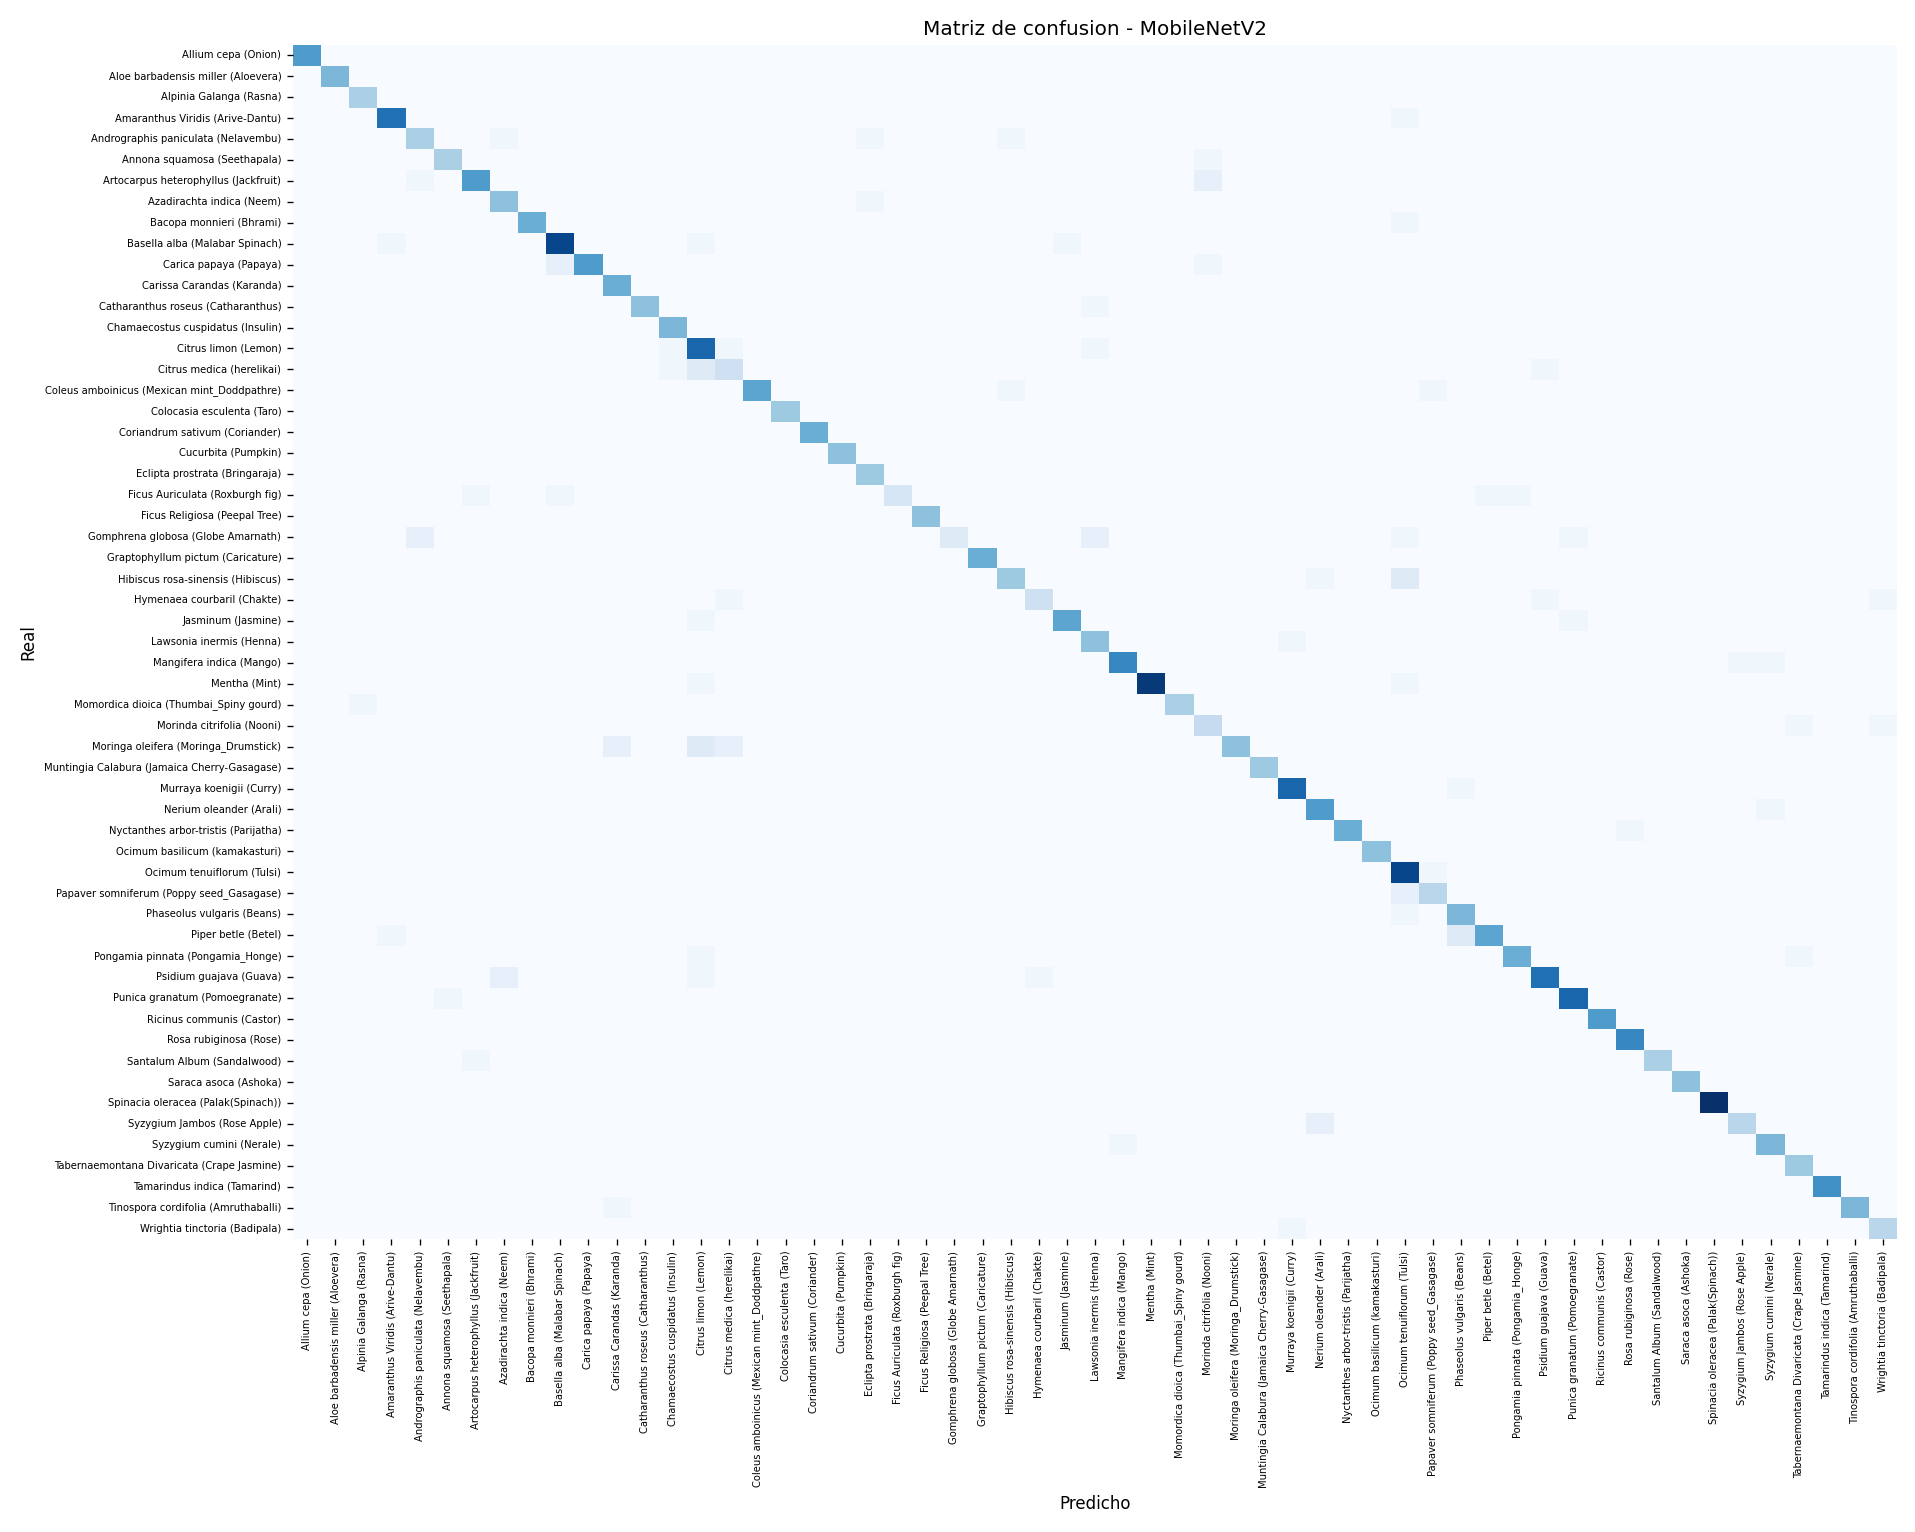

In [1]:
# resultados_comparacion: barras, curvas y matrices
print('Herbify GPU · ResNet50 93,0 % · EfficientNetB0 89,4 % · MobileNetV2 88,8 %')


## 5. MobileNetV3Small alumno del ResNet50 de Herbify

La última sección de `comparacion_resnet50_mobilenetv2.ipynb` entrena un MobileNetV3Small con la etiqueta real y las probabilidades del ResNet50 (temperatura 4, peso de la etiqueta 0,5). El profesor es el ResNet50 de 93,0 % en test.

La celda del notebook termina con `RuntimeError`: al evaluar no había vuelto a compilar el modelo. Los pesos sí se guardaron (`modelo_mobilenetv3_desde_resnet50.h5`, 4.0 MB, 972.009 parámetros). La evaluación posterior, registrada el 4 de noviembre de 2026 en `metricas_mobilenetv3_desde_resnet50.json`, da test **76,5 %**, top-3 90,7 %, 179 errores de 761. El entrenamiento duró 300,8 min. La última época anotada en el notebook, antes del error, marca 76,98 % de accuracy de validación.


Alumno MobileNetV3Small · test 76,5 % · top-3 90,7 % · 179 errores de 761


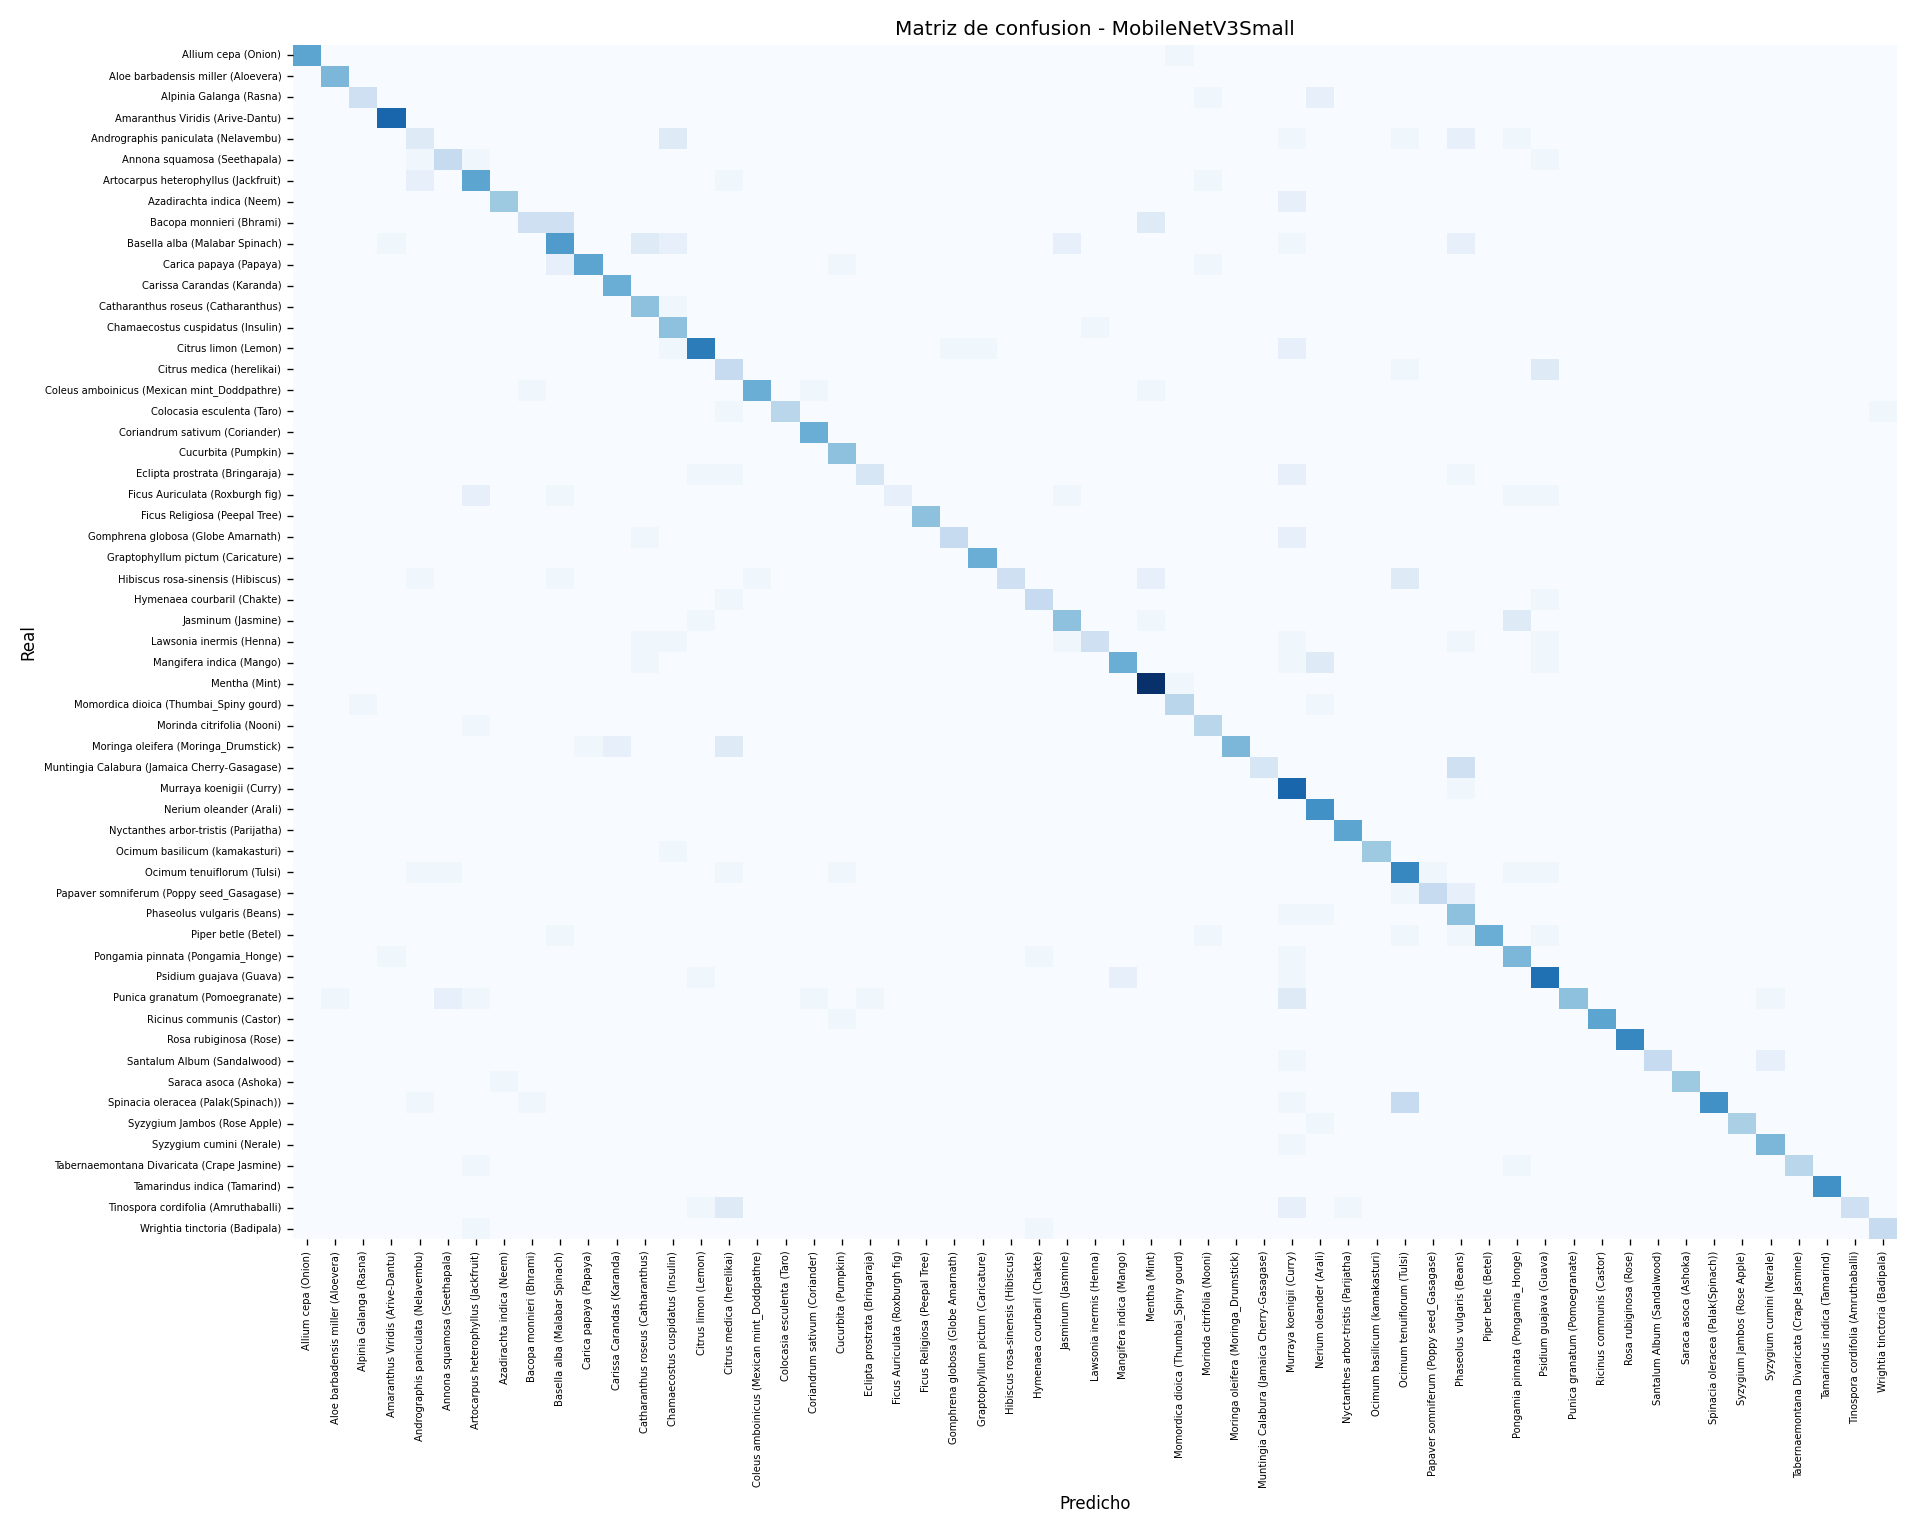

In [1]:
# Matriz guardada con metricas_mobilenetv3_desde_resnet50.json
print('Alumno MobileNetV3Small · test 76,5 % · top-3 90,7 % · 179 errores de 761')


## 6. Regional de 10 y de 20 especies

El modelo de 10 clases está archivado en `regional_colombia/resultados/`. Test **73,8 %**, 79 errores de 301. Dataset: iNaturalist (Colombia / Tolima) más Herbify en guayaba y ruda.

`entrenamiento_regional_colombia.ipynb` entrena el MobileNetV2 de 20 especies sobre 8.912 fotos (6.238 / 1.327 / 1.347). Fase 1: 20 épocas de 25 pedidas, validación final 65,2 %. Fase 2: 20/20 épocas, validación final 77,2 %. En test, **77,4 %**, 304 errores. El reporte del notebook da F1 macro 77,5 % y F1 ponderado 77,4 %. Esa corrida no usa multa L1/L2.

Las celdas de L1/L2 de ese notebook no tienen salida. La corrida con L1 = 1e-5 y L2 = 1e-4 está en el script y en `metricas_regional_l1l2.json`: test **71,9 %**, top-3 88,9 %, 378 errores, 81,1 min, mejor validación 73,2 %.


Regional · 10 especies 73,8 % · 20 especies 77,4 % · 20 especies con L1/L2 71,9 %


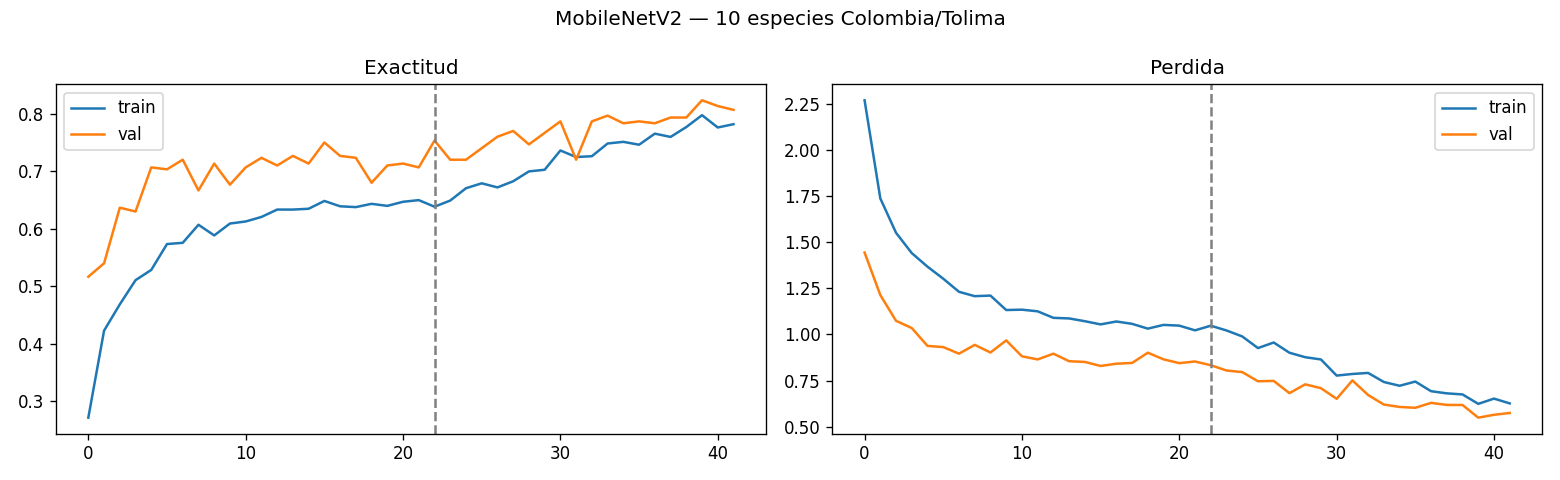

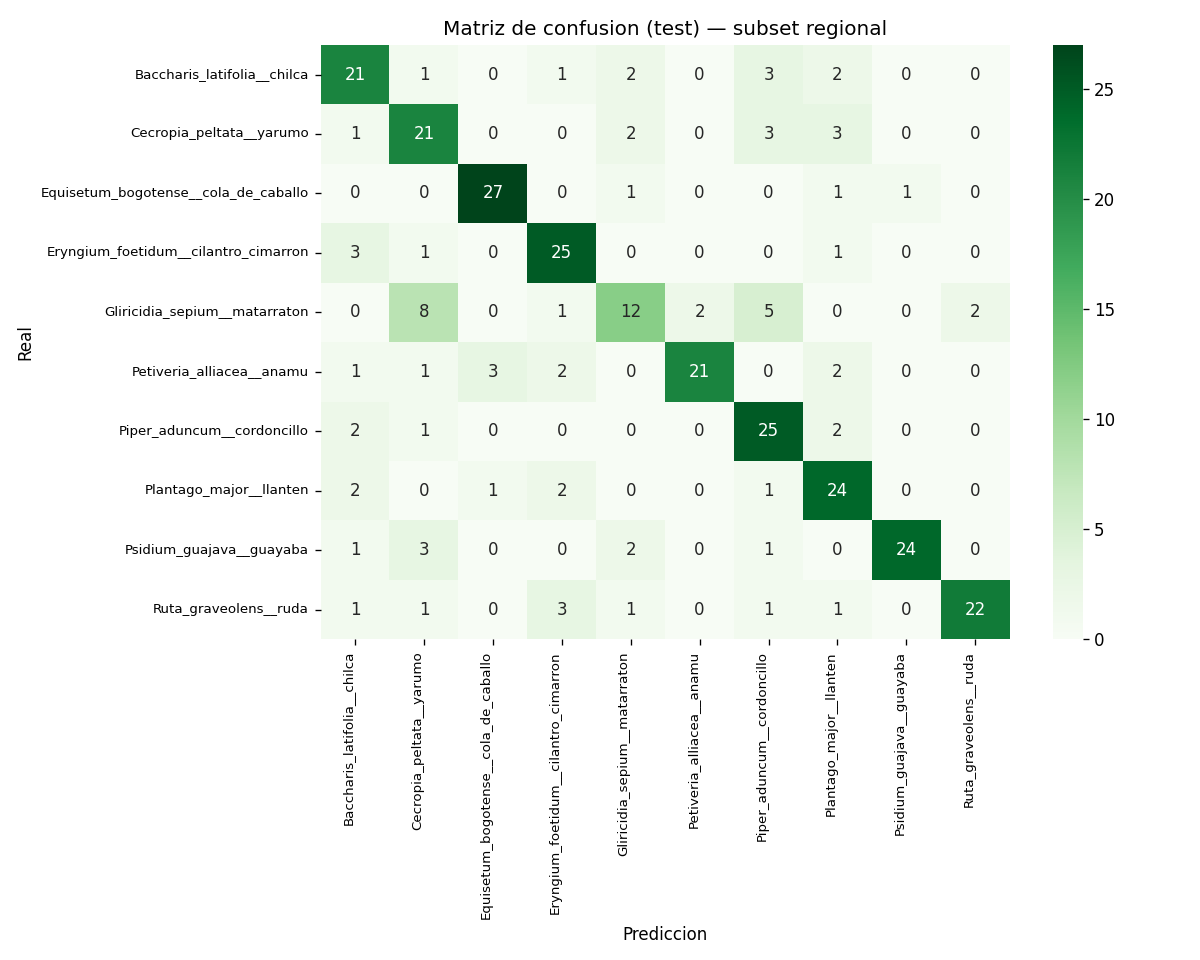

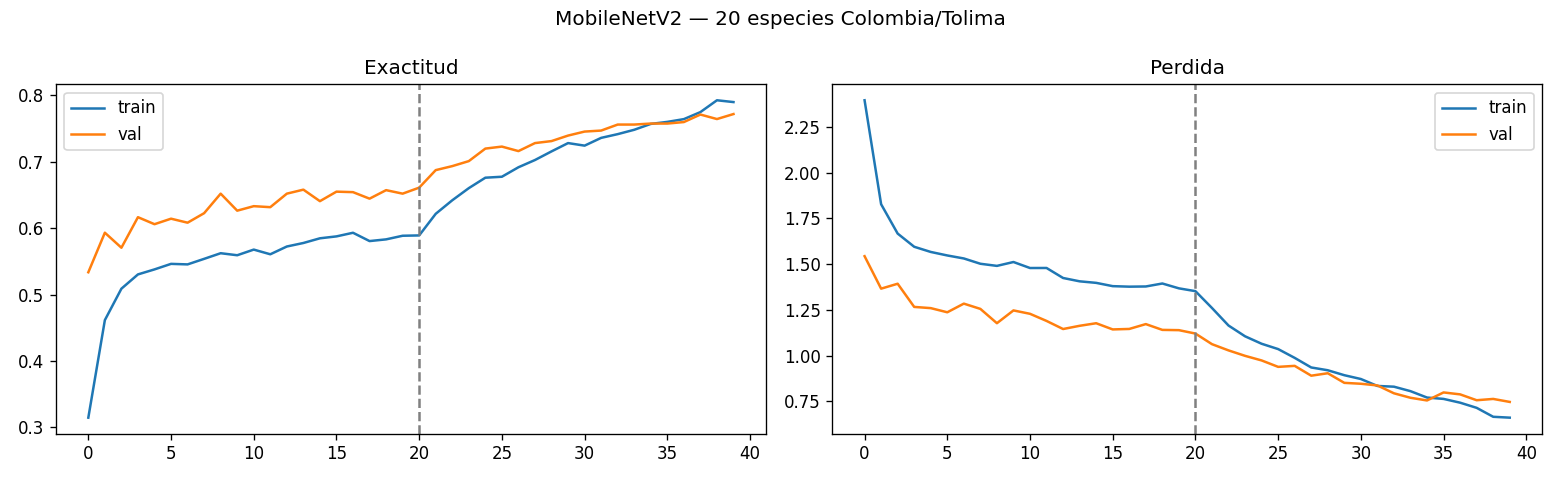

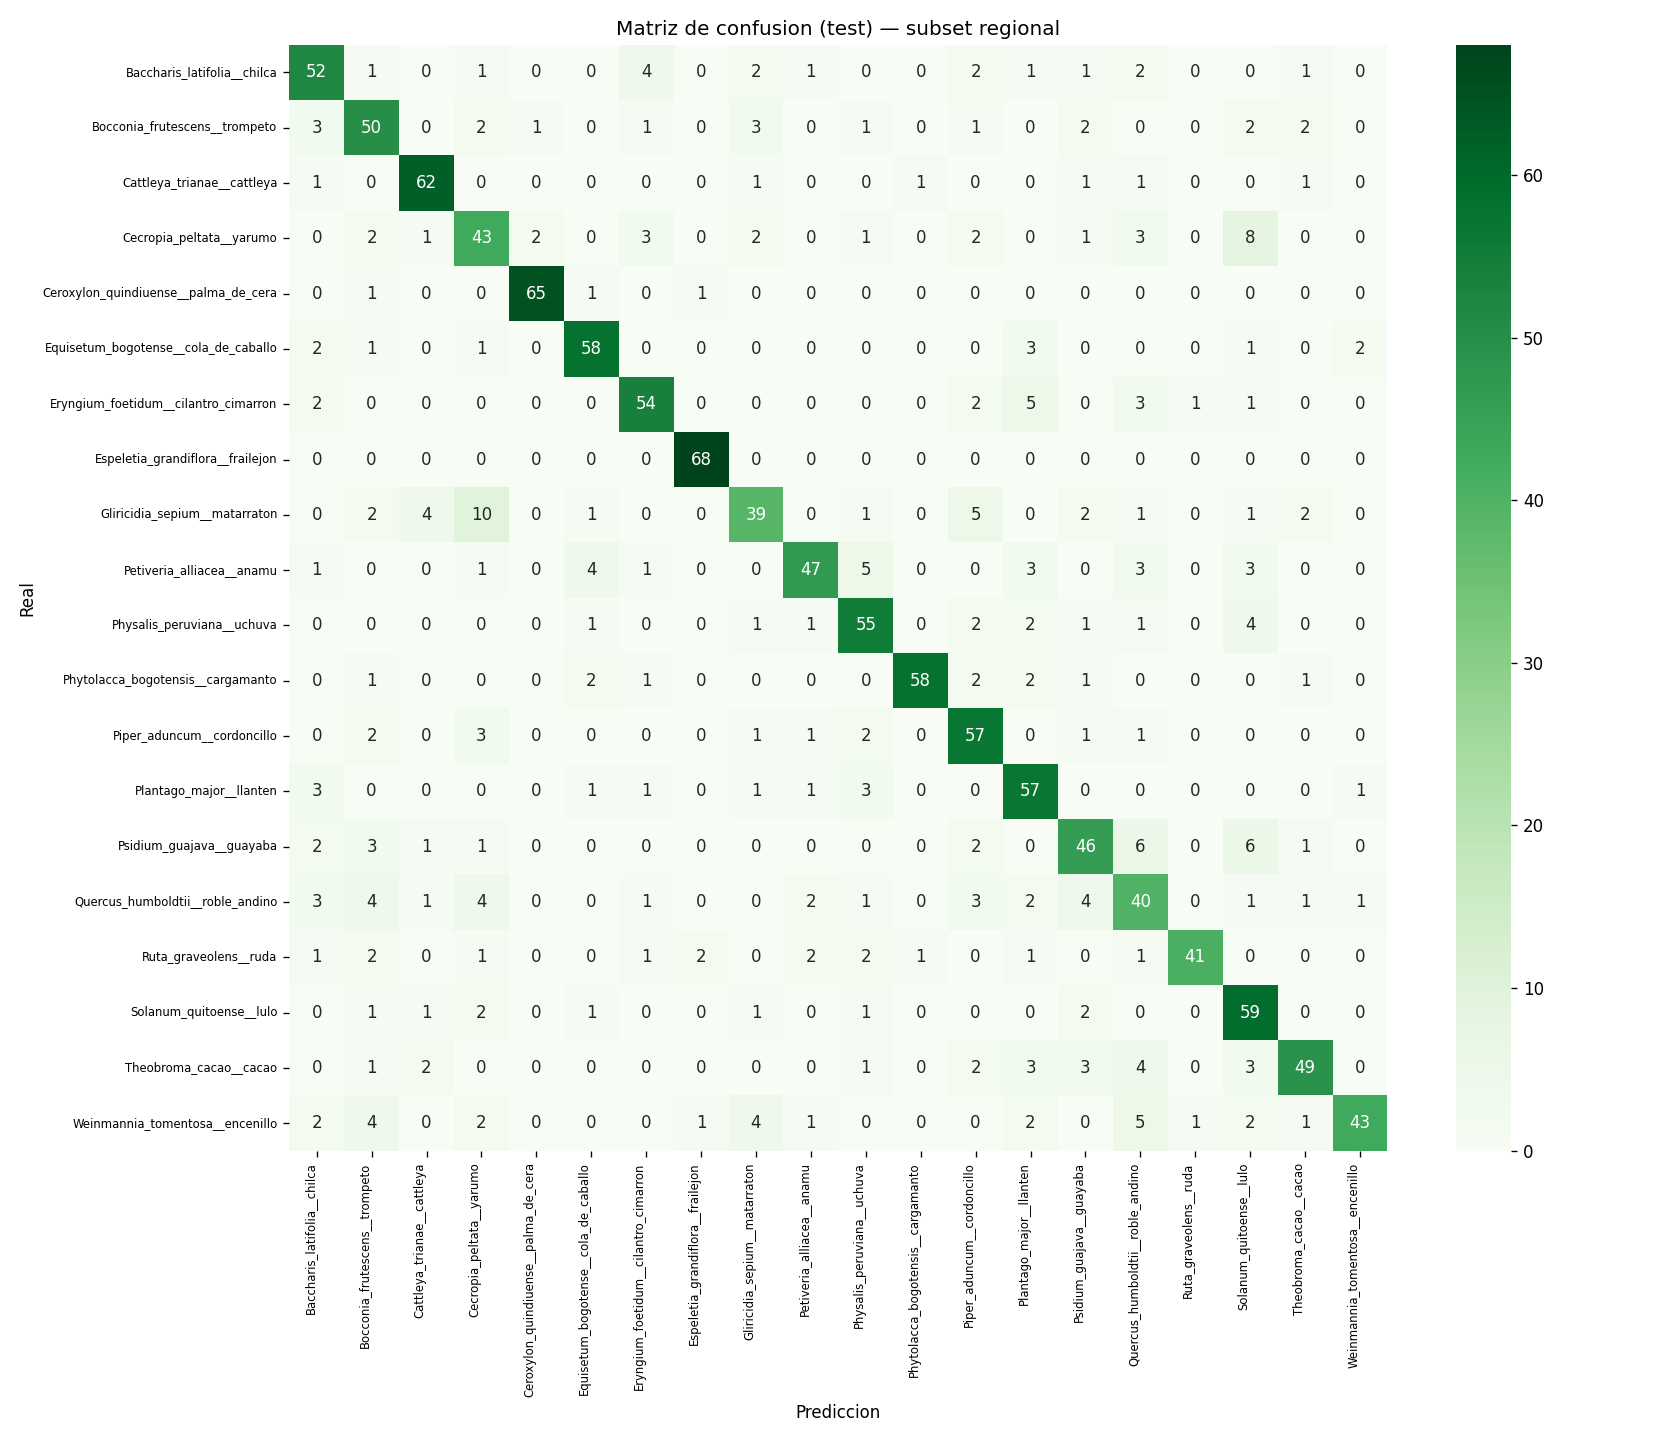

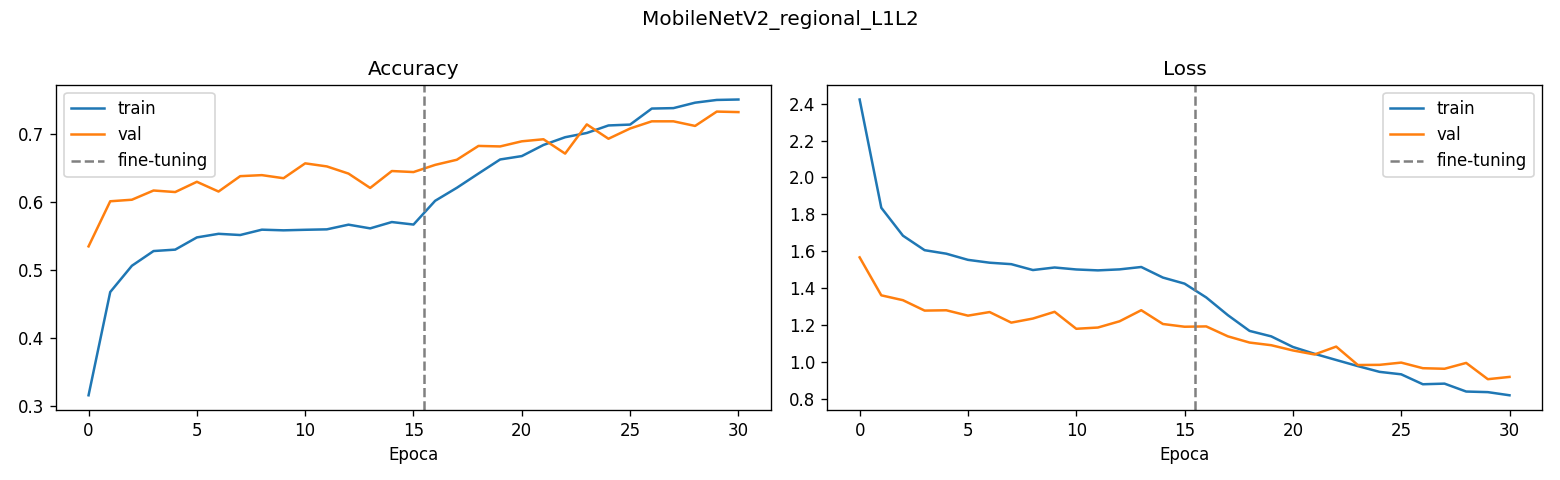

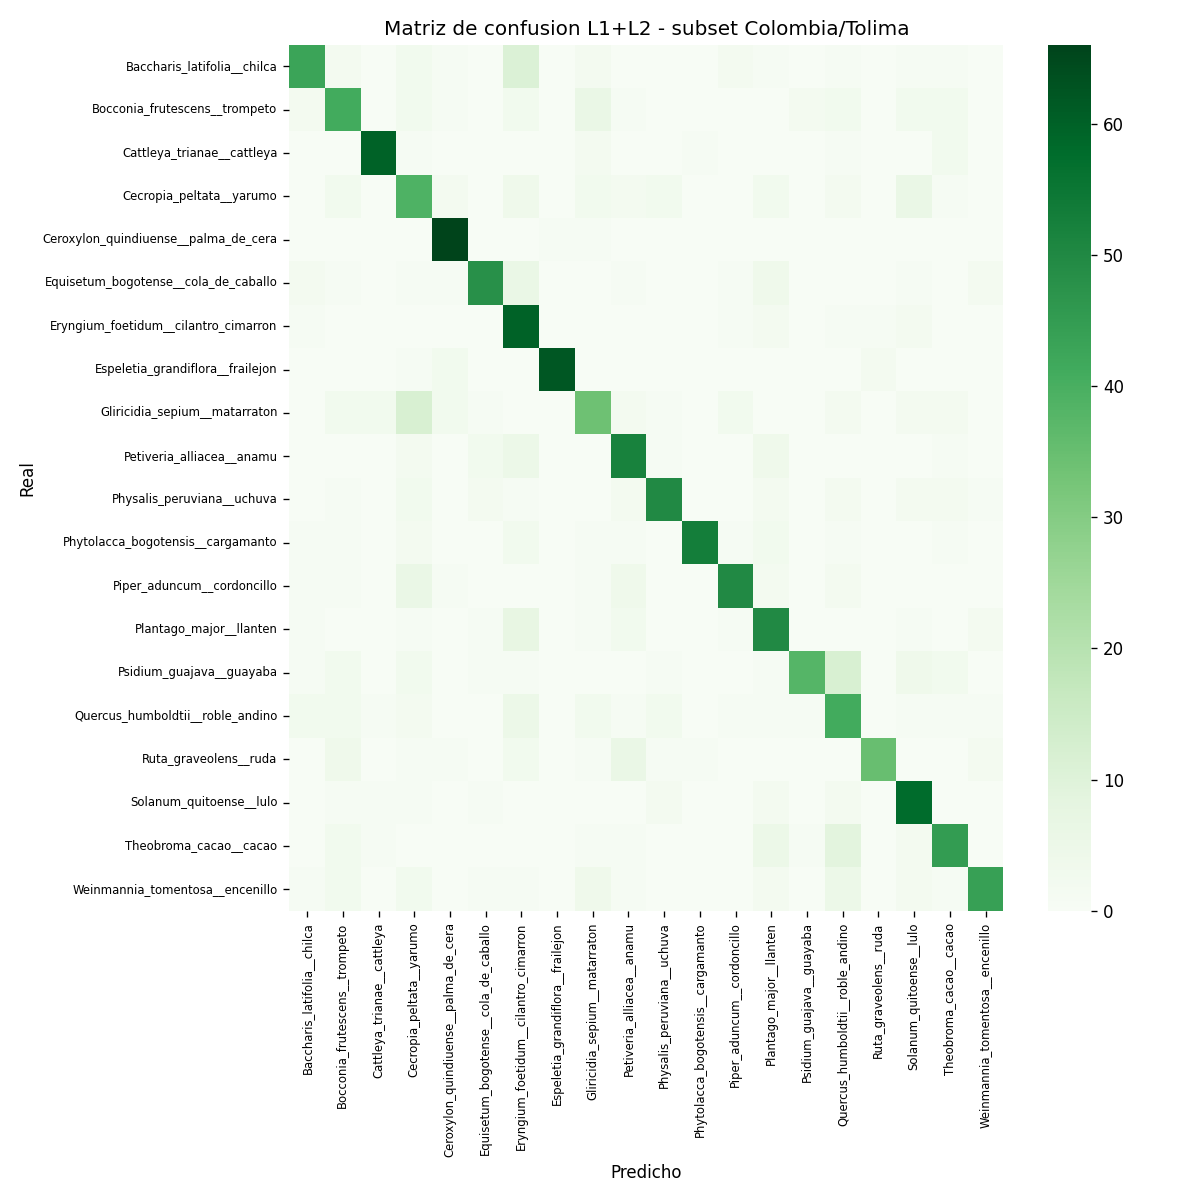

In [1]:
# Curvas y matrices de 10 especies, 20 especies y la variante L1/L2
print('Regional · 10 especies 73,8 % · 20 especies 77,4 % · 20 especies con L1/L2 71,9 %')


## 7. Regional de 29 especies: MobileNetV2, ResNet50 y el estudiante

Dataset `dataset_29`: 10.201 train, 2.178 validación, 2.201 test, 29 especies, iNaturalist más fotos de huerta. Split 70/15/15, semilla 42, imagen 224, lote 16.

MobileNetV2 (`metricas_regional_29.json`): fase 1 cortada en la época 17 de 25, fase 2 completa de 20. Test **68,0 %**, top-3 85,4 %, F1 ponderado 68,1 %, 705 errores, 157,3 min, mejor validación 70,7 %.

ResNet50, notebook `entrenamiento_resnet50_regional.ipynb`: 25 épocas de fase 1 y 20 de fase 2, 164,3 min. Test **76,5 %**, top-3 89,2 %, F1 ponderado 76,8 %, 517 errores, 23.647.133 parámetros, archivo de 90.53 MB. Mejor validación 78,3 %.

`entrenamiento_mobilenetv2_estudiante_regional.ipynb` no tiene salidas guardadas. El script `entrenar_estudiante_v2.py` sí terminó. El alumno imita al ResNet50 regional (temperatura 4, mitad etiqueta y mitad profesor). Fase 1: 22 épocas; fase 2: 20. Test **69,5 %**, top-3 84,4 %, F1 ponderado 69,7 %, 671 errores, 186,2 min.


29 especies · MobileNetV2 68,0 % · ResNet50 76,5 % · estudiante 69,5 %


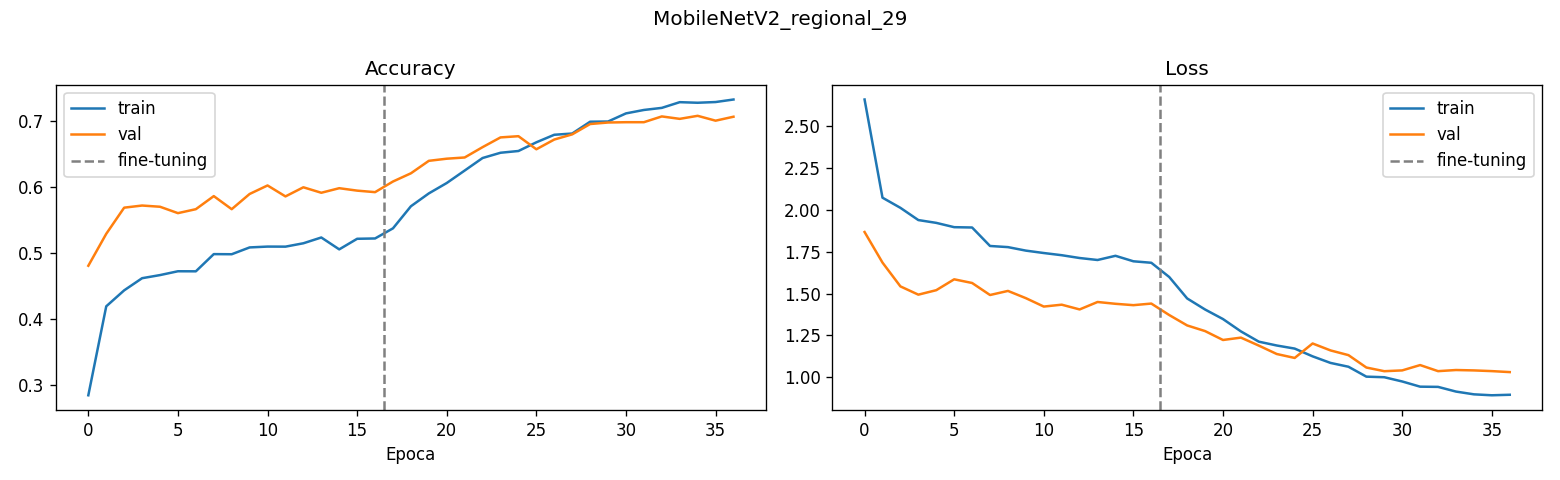

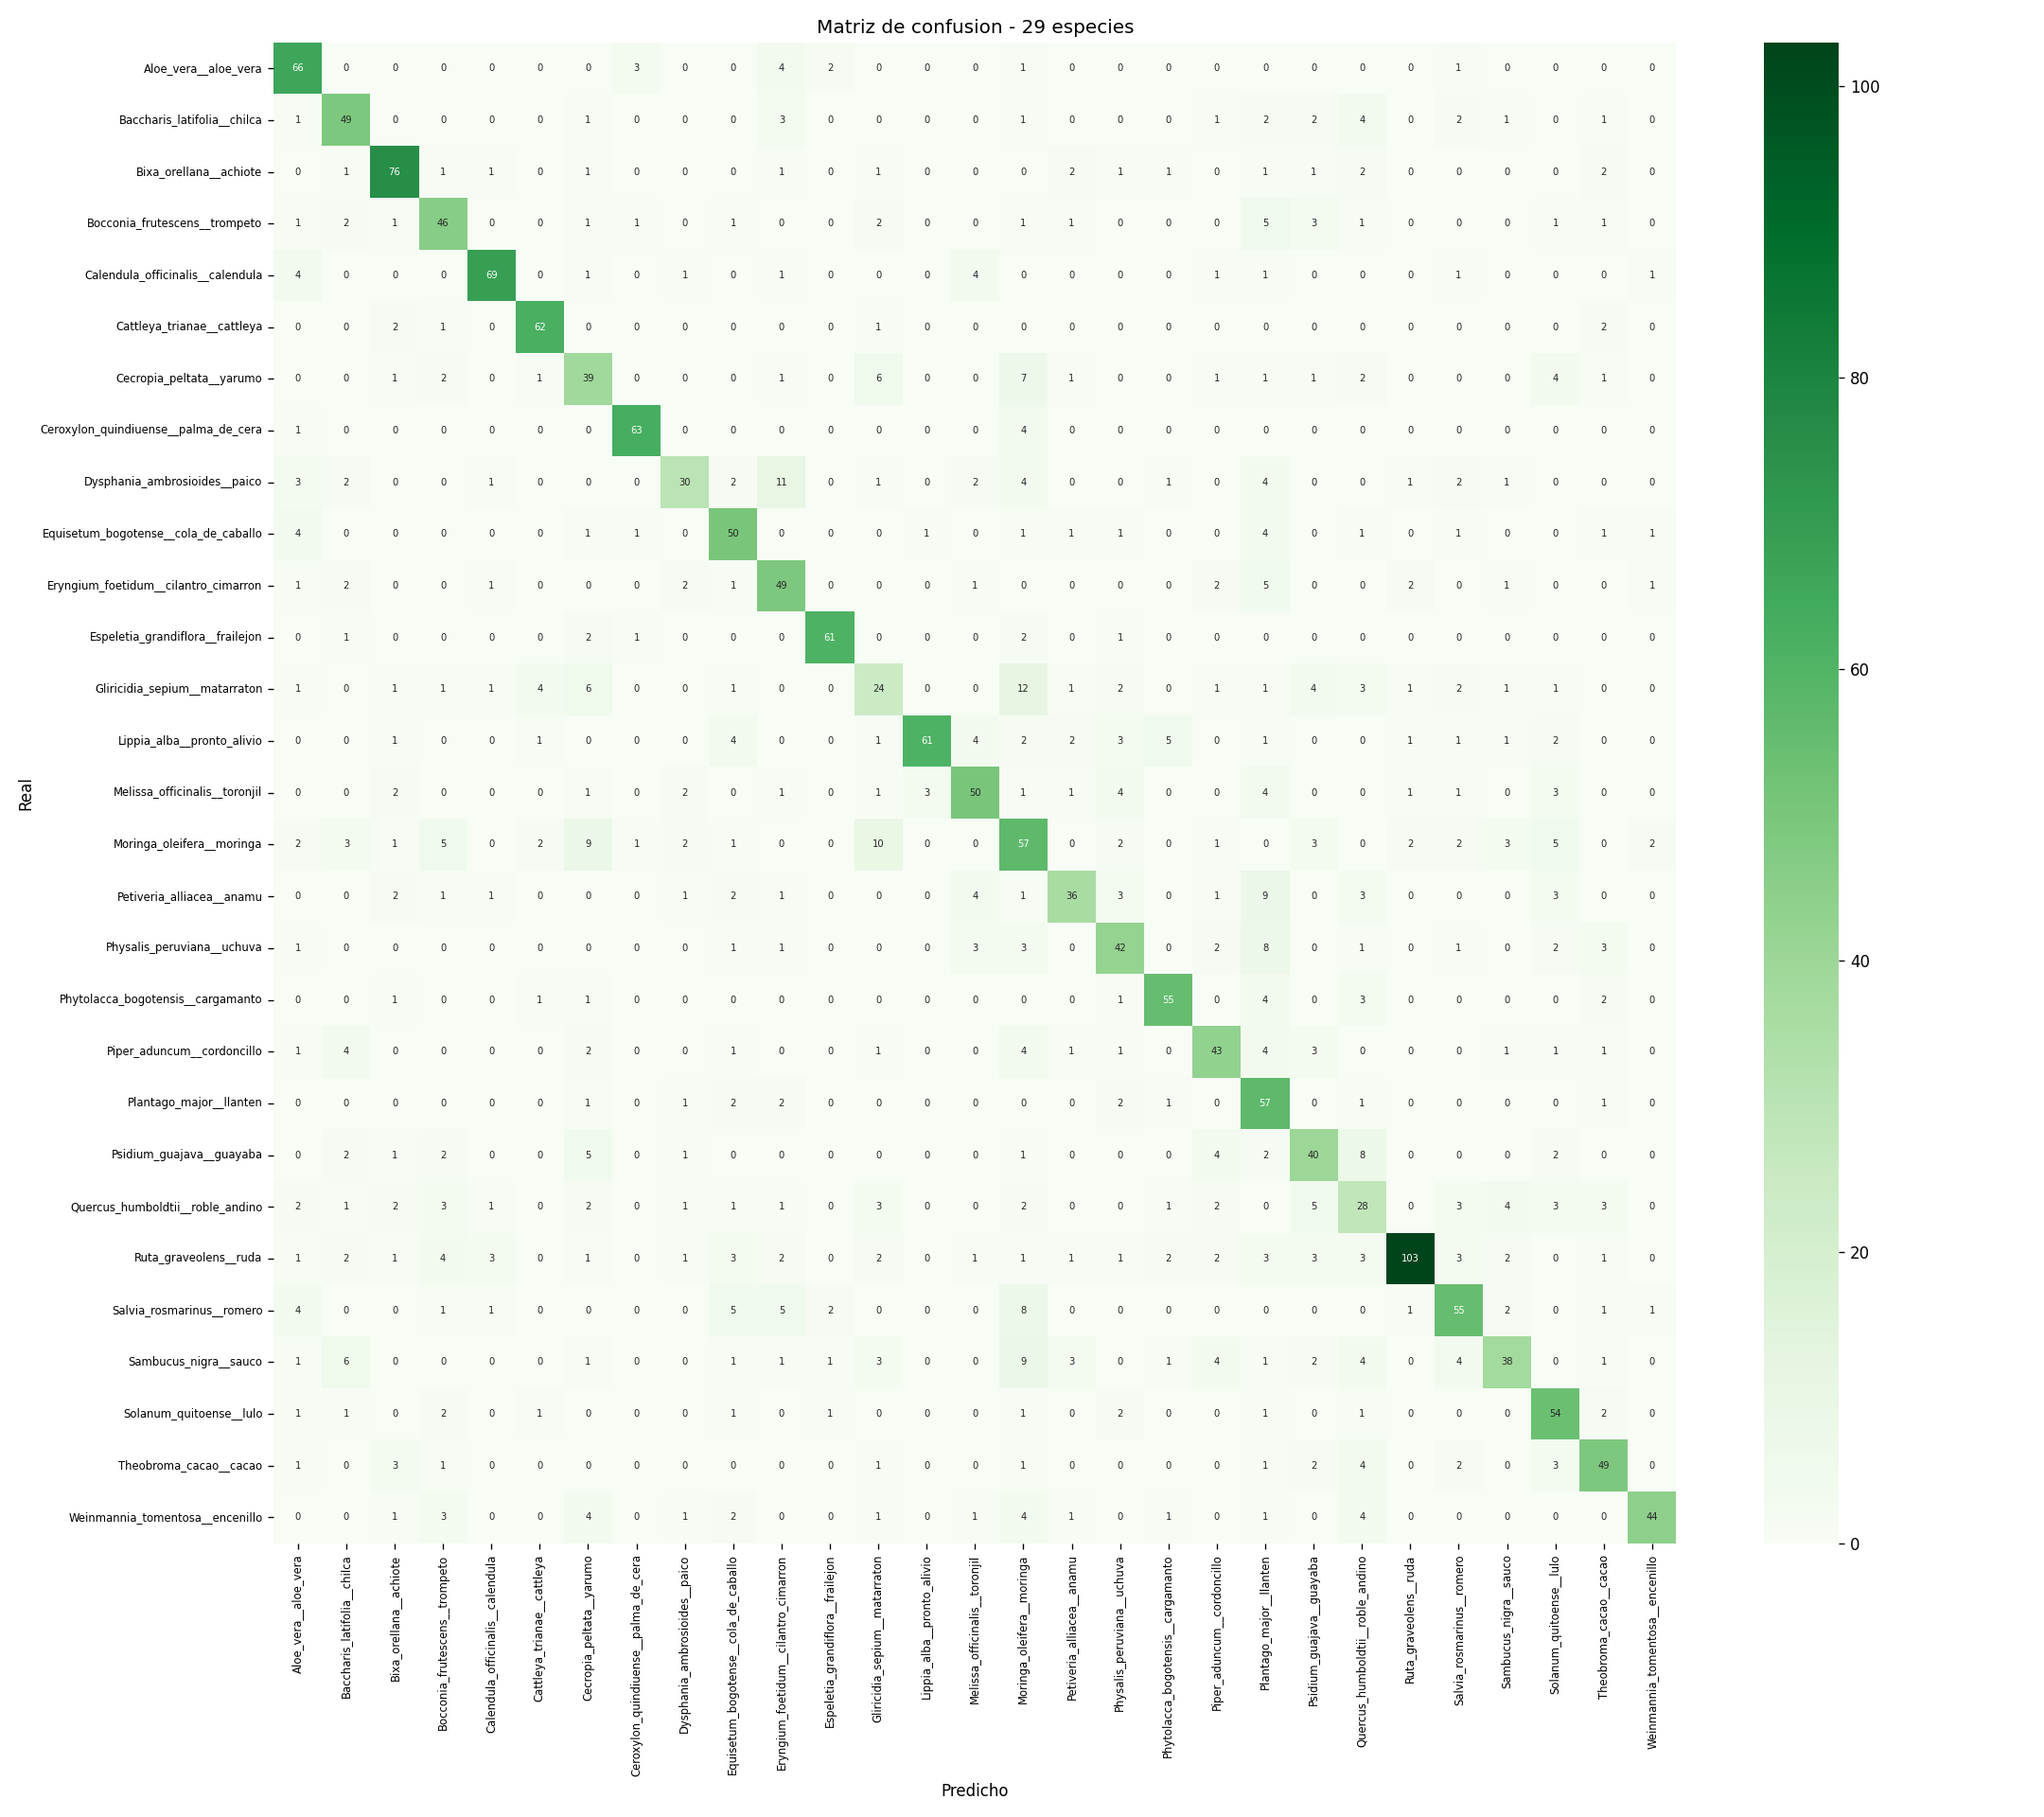

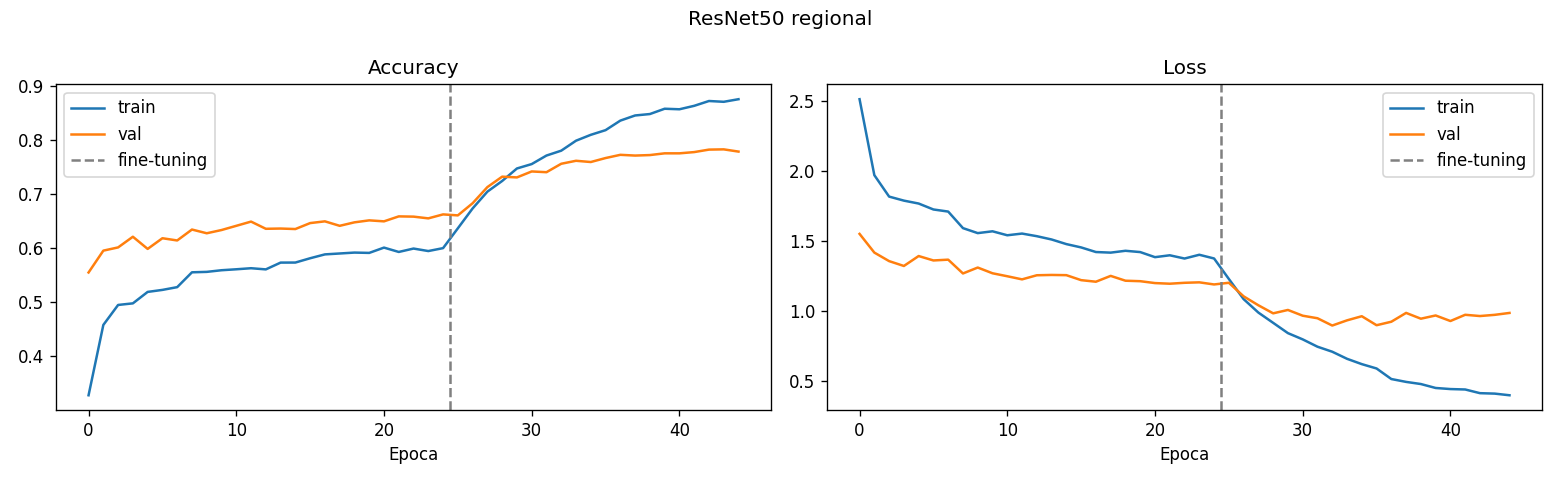

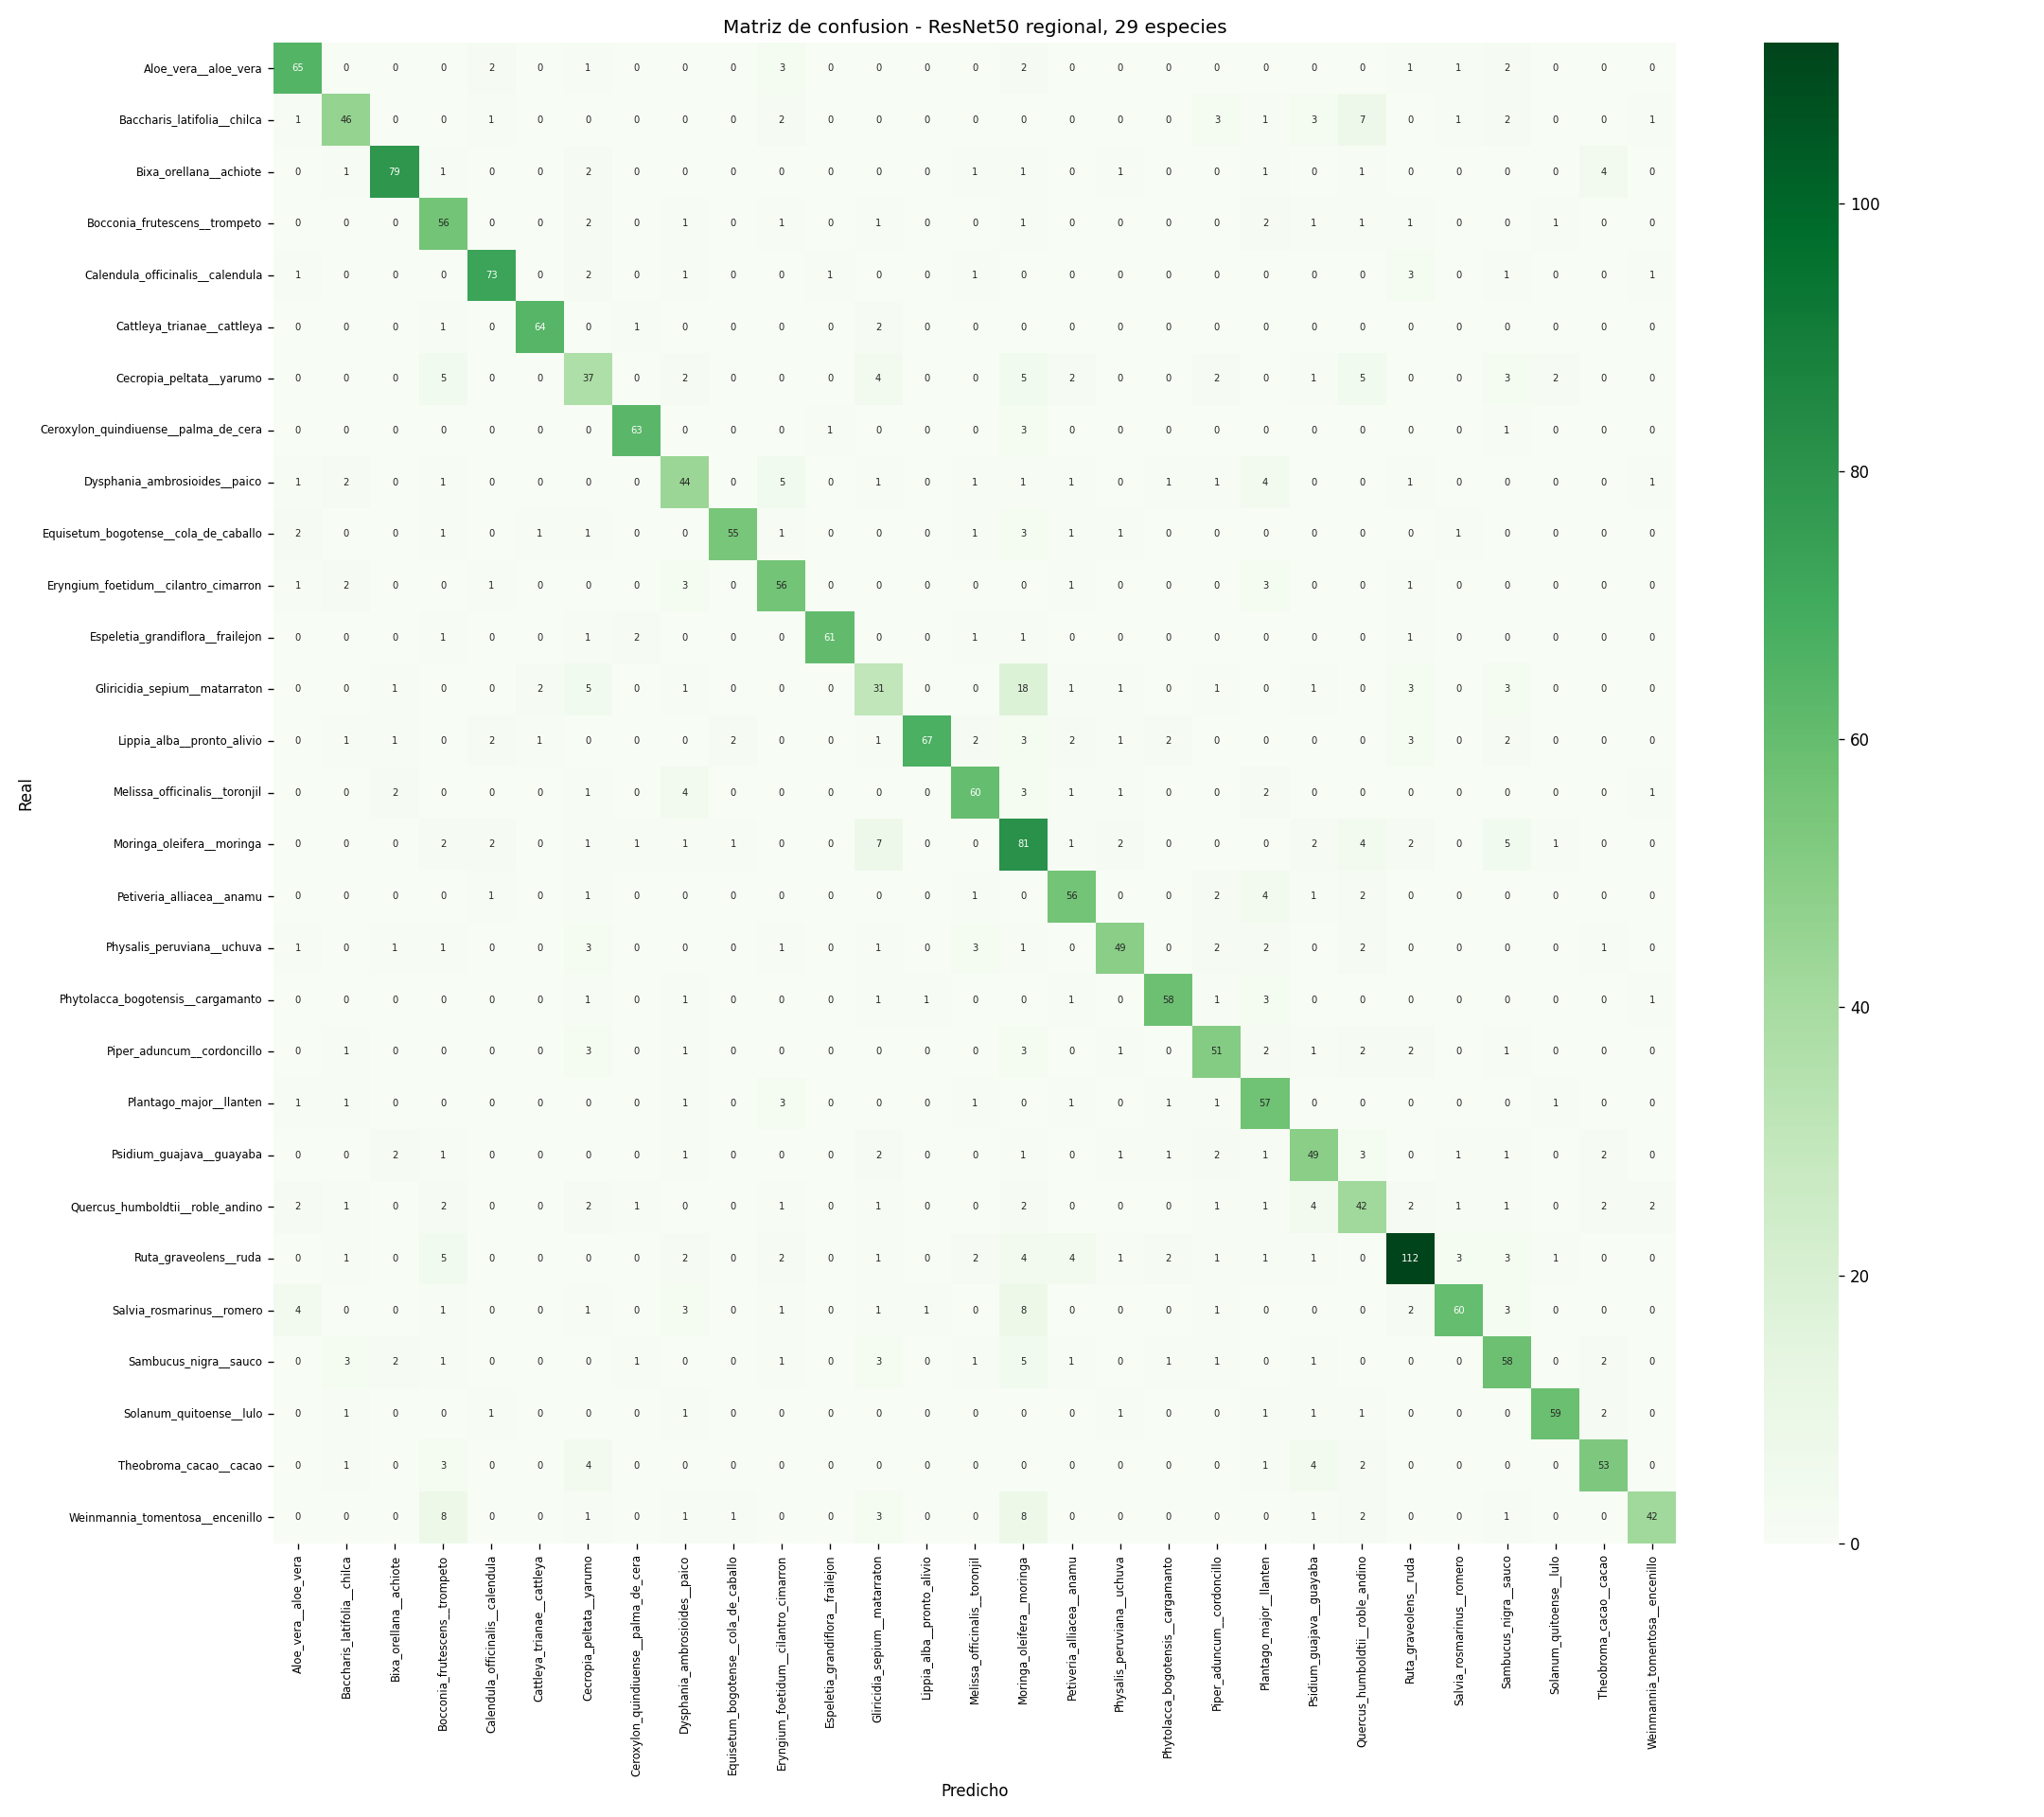

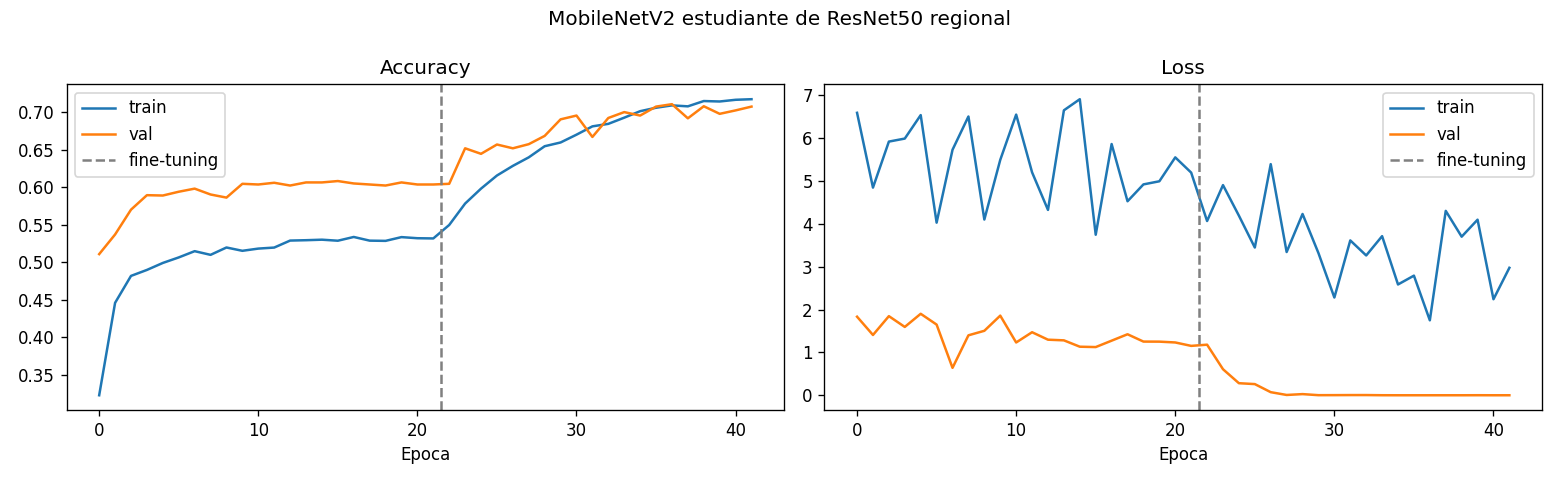

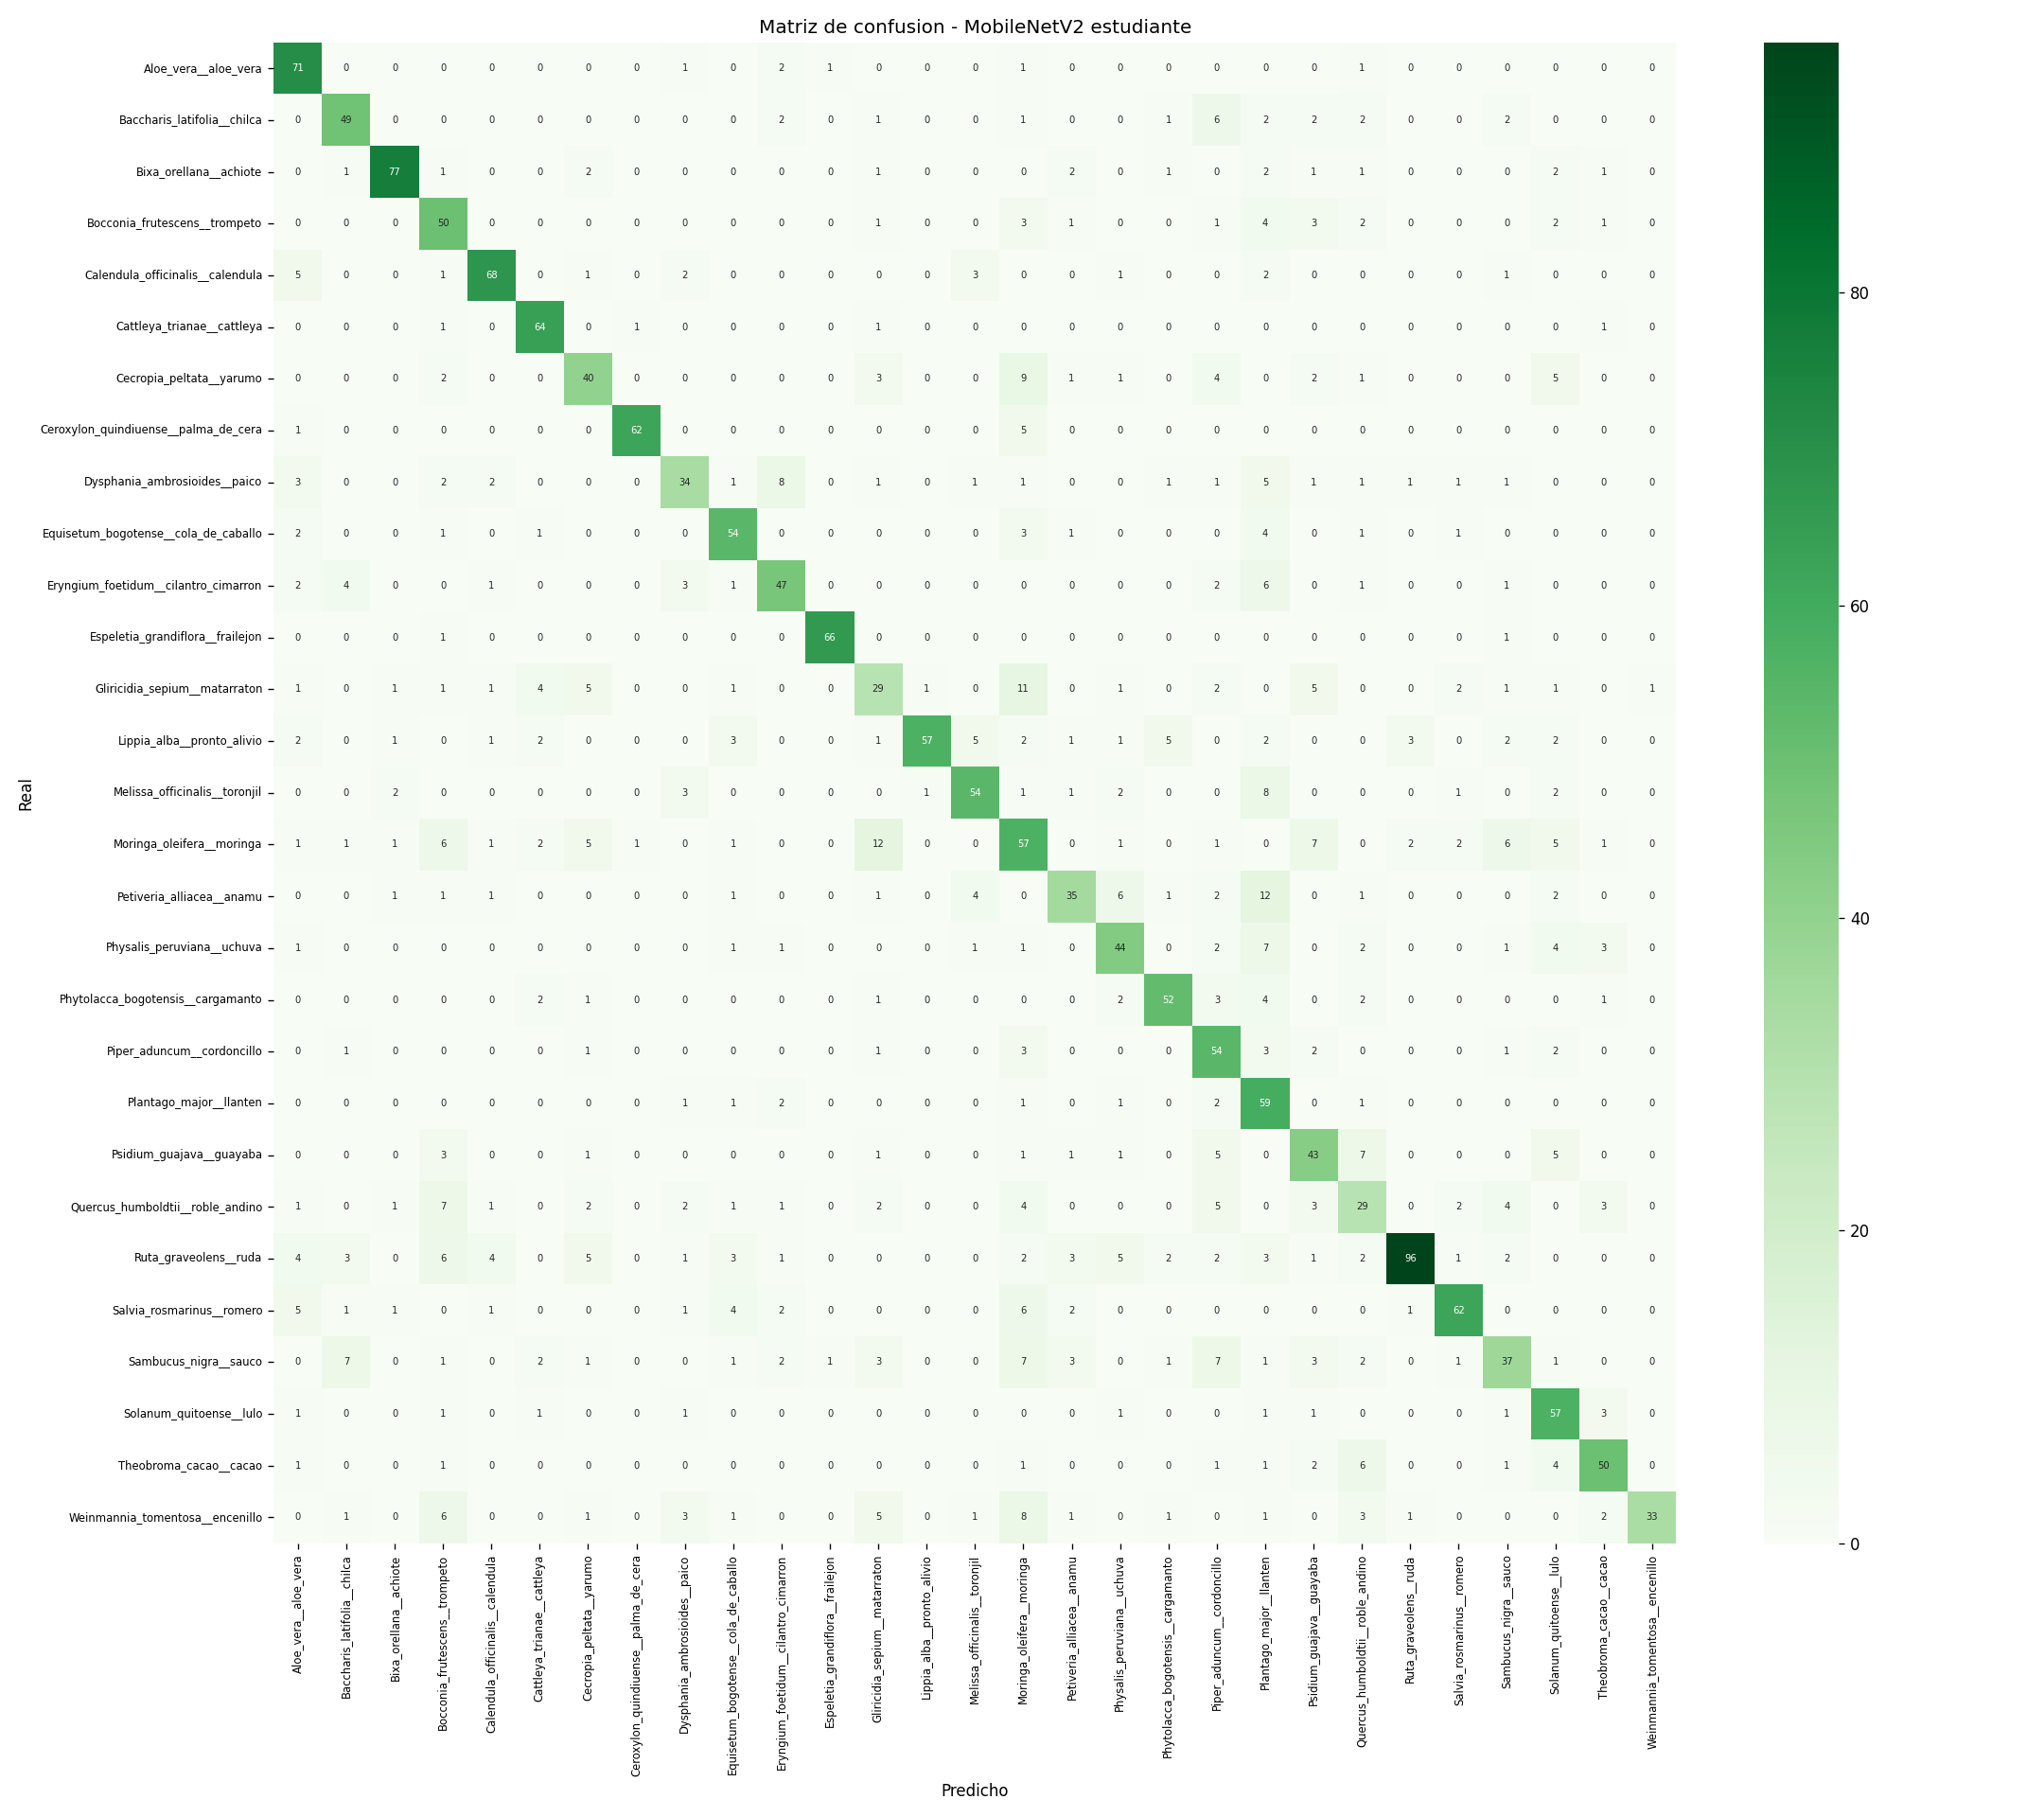

In [1]:
# Regional de 29 especies: MobileNetV2, ResNet50 y el estudiante
print('29 especies · MobileNetV2 68,0 % · ResNet50 76,5 % · estudiante 69,5 %')
